# NASA Space Explorer — Exploratory Data Analysis

Northwestern MLDS 400 · Data Engineering Project

Our pipeline collects NASA Image and Video Library metadata, cleans it, and loads it into PostgreSQL. In this notebook we query that database and tell three stories about what is actually inside the archive:

1. **Behind the 2014 Peak:** why 2014 has the most records, and which NASA missions show up in that peak.
2. **Beyond Planet Photos:** what kinds of records the big NASA centers contribute.
3. **Missions, Sources & Locations:** which missions, credit sources, and places the metadata mentions most.

Section 4 keeps our earlier descriptive checks (topic distribution, overlap, completeness, and date anomalies), and Section 5 lists sources and reproducibility notes. Every number is computed from the database when the notebook runs.

---
## Section 0 — Dataset & Methods

**Data source.** NASA Image and Video Library search results for nine topics (Mercury, Venus, Earth, Mars, Jupiter, Saturn, Uranus, Neptune, and Galaxy), stored in two PostgreSQL tables:

- `nasa_records`: one row per image, keyed by `(source_api, source_id)`, where `source_id` is the NASA ID.
- `nasa_search_matches`: one row per image–topic match, so one image can belong to several topics.

**Scope.** `source_api = 'nasa_library'` and `media_type = 'image'`.

**Counting rule.** Every count below is a count of *distinct NASA IDs*. Where we need topics, we use `EXISTS` instead of a join, so an image is never counted twice.

**How to run.** Use the **nasa-space-explorer** Conda kernel. The notebook reads the database URL from `.env.neon` (`NEON_DATABASE_URL`) when that file exists, or from `.env` (`DATABASE_URL`) otherwise. Both files are gitignored, and the connection string is never printed.

In [1]:
# Import the libraries used throughout the report.
import os
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import requests
from dotenv import dotenv_values, load_dotenv
from IPython.display import HTML, Markdown, display
from plotly.subplots import make_subplots
from sqlalchemy import create_engine, text

# Locate the repository from either the project root or notebooks/.
working_directory = Path.cwd().resolve()
project_root = next(
    (path for path in [working_directory, *working_directory.parents]
     if (path / "dashboard/analysis_rules.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from the project root or the notebooks directory.")
if Path(sys.prefix).name != "nasa-space-explorer":
    raise RuntimeError("Select the nasa-space-explorer Conda kernel before running all cells.")

# The text rules (mission aliases, title groups, location groups) are shared with the dashboard.
sys.path.insert(0, str(project_root / "dashboard"))
import analysis_rules as rules  # noqa: E402

# Exported, presentation-ready charts go here.
ASSET_DIR = project_root / "assets/eda"
ASSET_DIR.mkdir(parents=True, exist_ok=True)

# Interactive charts in Jupyter, plus a static PNG copy so the charts also show on GitHub.
pio.renderers.default = "plotly_mimetype+png"
print(f"Python {sys.version.split()[0]} · environment: {Path(sys.prefix).name}")

Python 3.11.18 · environment: nasa-space-explorer


Now we connect. Prefer the Neon URL in `.env.neon`; otherwise fall back to `DATABASE_URL`. Every session is **read-only** (`default_transaction_read_only=on`), and one `REPEATABLE READ` transaction keeps all queries on the same snapshot. Dates are compared with the current date in America/Chicago.

In [2]:
# Read the URL without printing it. The project uses the psycopg2 driver.
neon_file = project_root / ".env.neon"
if neon_file.is_file():
    database_url = dotenv_values(neon_file).get("NEON_DATABASE_URL")
    url_source = ".env.neon"
else:
    load_dotenv(project_root / ".env", override=False)
    database_url = os.environ.get("DATABASE_URL")
    url_source = ".env"
if not database_url:
    raise RuntimeError("No database URL found. Add NEON_DATABASE_URL to .env.neon or DATABASE_URL to .env.")
database_url = "postgresql+psycopg2://" + database_url.split("://", 1)[1]

engine = create_engine(
    database_url,
    isolation_level="REPEATABLE READ",
    hide_parameters=True,
    connect_args={"options": "-c default_transaction_read_only=on -c timezone=America/Chicago"},
)
del database_url
connection = engine.connect()
snapshot = connection.begin()


def sql(query, **params):
    """Run one read-only query on the shared snapshot and return a DataFrame."""
    return pd.read_sql(text(query), connection, params=params)


connection_check = sql("""
    SELECT current_database() AS database_name, CURRENT_DATE::text AS analysis_date,
           current_setting('transaction_read_only') AS read_only,
           current_setting('transaction_isolation') AS isolation_level
""")
assert connection_check.loc[0, "read_only"] == "on"
assert connection_check.loc[0, "isolation_level"] == "repeatable read"
as_of_date = connection_check.loc[0, "analysis_date"]
print(f"Connected to database '{connection_check.loc[0, 'database_name']}' (URL from {url_source}) · "
      f"read-only snapshot · analysis date: {as_of_date}")

Connected to database 'neondb' (URL from .env.neon) · read-only snapshot · analysis date: 2026-11-25


All charts share the dashboard's "Starlight Observatory" palette: muted blue for data, navy for the highlight, and gold for annotations. `show_and_save` displays a chart and, when given a file name, exports a PNG to `assets/eda/`.

In [3]:
# One visual style for every chart and table.
NAVY = "#17324D"
BLUE = "#4A93C6"
LIGHT_BLUE = "#A9CBE4"
GOLD = "#C9A86A"
GREY = "#C8D3DD"
MUTED = "#60758A"
GRID = "#E6EEF5"
SCOPE = "r.source_api = 'nasa_library' AND r.media_type = 'image'"
HISTORICAL = "r.date IS NOT NULL AND isfinite(r.date) AND r.date <= CURRENT_DATE"

pio.templates["nasa_eda"] = go.layout.Template(layout=go.Layout(
    template="plotly_white",
    font=dict(family="Arial, sans-serif", size=13, color=NAVY),
    title=dict(x=0, xanchor="left", font=dict(size=19, color=NAVY)),
    paper_bgcolor="white", plot_bgcolor="white",
    colorway=[BLUE, NAVY, GOLD, LIGHT_BLUE],
    margin=dict(l=80, r=60, t=95, b=60),
    xaxis=dict(gridcolor=GRID, zeroline=False, automargin=True),
    yaxis=dict(gridcolor=GRID, zeroline=False, automargin=True),
    hoverlabel=dict(bgcolor="white", font_size=13),
))
pio.templates.default = "nasa_eda"
CHART_CONFIG = {"displaylogo": False, "responsive": True, "scrollZoom": False}
TABLE_STYLE = [
    {"selector": "th", "props": [("background-color", NAVY), ("color", "white"),
                                  ("padding", "8px 12px"), ("text-align", "left")]},
    {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #E6EEF5")]},
    {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#F5F8FC")]},
    {"selector": "table", "props": [("border-collapse", "collapse"),
                                     ("font-family", "Arial, sans-serif"), ("font-size", "13px")]},
]
exported_files = []


def fmt_number(value):
    """Whole numbers with thousands separators; other values with two decimals."""
    return f"{value:,.0f}" if float(value).is_integer() else f"{value:,.2f}"


def show_table(frame, formats=None):
    display(frame.style.format(formats or {}).hide(axis="index").set_table_styles(TABLE_STYLE))


def show_and_save(figure, filename=None, width=1200):
    """Display a chart and optionally export it as a presentation-ready PNG."""
    if filename:
        path = ASSET_DIR / filename
        figure.write_image(path, width=width, height=figure.layout.height or 600, scale=2)
        exported_files.append(path)
    figure.show(config=CHART_CONFIG)


def image_cards(frame, caption_column):
    """Show real NASA thumbnails with a link to the original record and a text fallback."""
    cards = []
    for row in frame.itertuples(index=False):
        credit = f"<br>Credit: {row.credit}" if isinstance(row.credit, str) and row.credit.strip() else ""
        cards.append(
            f'<div style="width:31%;min-width:220px;font-family:Arial;font-size:12px;color:{NAVY}">'
            f'<img src="{row.image_url}" alt="Image preview unavailable — view the original NASA record." '
            f'style="width:100%;height:190px;object-fit:cover;border-radius:8px;background:#E6EEF6">'
            f'<div style="margin-top:6px;font-weight:bold">{row.title}</div>'
            f'<div style="color:{MUTED}">{getattr(row, caption_column)} · {row.date} · NASA ID {row.source_id}'
            f'{credit}<br><a href="{row.page_url}" target="_blank">View on NASA Image Library</a></div></div>'
        )
    display(HTML('<div style="display:flex;gap:14px;flex-wrap:wrap">' + "".join(cards) + "</div>"))

### 0.1 Basic data checks

First we confirm the schema we rely on actually exists, instead of assuming optional fields are there.

In [4]:
# Inspect the actual schema instead of assuming optional fields exist.
schema = pd.read_sql(text("""
    SELECT table_name, column_name, data_type, is_nullable
    FROM information_schema.columns
    WHERE table_schema = 'public'
      AND table_name IN ('nasa_records', 'nasa_search_matches')
    ORDER BY table_name, ordinal_position
"""), connection)
required_fields = {"source_api", "source_id", "title", "date", "media_type", "image_url",
                   "explanation", "credit", "center", "location", "keywords"}
record_schema = schema.loc[schema["table_name"].eq("nasa_records")]
assert required_fields <= set(record_schema["column_name"])
assert record_schema.set_index("column_name").loc["date", "data_type"] == "date"
assert record_schema.set_index("column_name").loc["keywords", "data_type"] == "jsonb"
print(f"Schema verified: {len(record_schema)} image fields; date is DATE and keywords is JSONB.")

Schema verified: 14 image fields; date is DATE and keywords is JSONB.


Next we profile the image table and the relationship table separately, so the relationship rows never multiply the image counts. The asserts check that NASA IDs are unique and that no relationship points to a missing image.

In [5]:
# Calculate the image profile without joining and multiplying image rows.
profile_sql = """
SELECT COUNT(*) AS total_images,
       COUNT(DISTINCT (source_api, source_id)) AS unique_image_keys,
       MIN(date) FILTER (WHERE isfinite(date))::text AS earliest_date,
       MAX(date) FILTER (WHERE isfinite(date))::text AS latest_date,
       MIN(date) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE)::text AS historical_start,
       MAX(date) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE)::text AS historical_end,
       COUNT(*) FILTER (WHERE date IS NULL) AS missing_dates,
       COUNT(*) FILTER (WHERE NOT isfinite(date)) AS nonfinite_dates,
       COUNT(*) FILTER (WHERE isfinite(date) AND date > CURRENT_DATE) AS future_dates,
       COUNT(*) FILTER (WHERE isfinite(date) AND date <= CURRENT_DATE) AS historical_images,
       COUNT(*) FILTER (WHERE NOT COALESCE(title ~ '[^[:space:]]', FALSE)) AS missing_titles,
       COUNT(*) FILTER (WHERE title = 'Untitled NASA Image') AS placeholder_titles,
       COUNT(*) FILTER (WHERE NOT COALESCE(image_url ~ '[^[:space:]]', FALSE)) AS missing_image_urls
FROM nasa_records
WHERE source_api = 'nasa_library' AND media_type = 'image'
"""
profile = pd.read_sql(text(profile_sql), connection).iloc[0]

# Check relationship totals and integrity using the full source key.
relationship_profile = pd.read_sql(text("""
    SELECT COUNT(*) AS relationships,
           COUNT(DISTINCT (m.source_api, m.source_id, m.search_keyword)) AS unique_relationships,
           COUNT(DISTINCT m.search_keyword) AS search_topics
    FROM nasa_search_matches AS m
    JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
"""), connection).iloc[0]
orphan_count = connection.execute(text("""
    SELECT COUNT(*) FROM nasa_search_matches AS m
    LEFT JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_id IS NULL
""")).scalar_one()
total_images = int(profile["total_images"])
total_relationships = int(relationship_profile["relationships"])
assert total_images > 0
assert total_images == profile["unique_image_keys"]
assert total_relationships == relationship_profile["unique_relationships"]
assert orphan_count == 0

overview = pd.DataFrame({
    "Dataset Measure": ["Unique images", "Image–topic relationships", "Search topics",
                        "Earliest stored date", "Latest stored date", "Historical dates used",
                        "Analysis cutoff (America/Chicago)"],
    "Value": [f"{total_images:,}", f"{total_relationships:,}",
              str(int(relationship_profile["search_topics"])),
              profile["earliest_date"], profile["latest_date"],
              f"{profile['historical_start']} to {profile['historical_end']}", as_of_date],
})
display(overview.style.hide(axis="index").set_table_styles(TABLE_STYLE))
quality_profile = pd.DataFrame({
    "Check": ["Missing or blank titles", "Normalized placeholder titles", "Missing or blank image URLs",
              "NULL dates", "Non-finite dates", "Future-dated records", "Orphan topic relationships"],
    "Records": [int(profile["missing_titles"]), int(profile["placeholder_titles"]),
                int(profile["missing_image_urls"]), int(profile["missing_dates"]),
                int(profile["nonfinite_dates"]), int(profile["future_dates"]), int(orphan_count)],
})
display(quality_profile.style.format({"Records": "{:,.0f}"}).hide(axis="index").set_table_styles(TABLE_STYLE))

Dataset Measure,Value
Unique images,"73,937"
Image–topic relationships,"80,809"
Search topics,9
Earliest stored date,1912-03-23
Latest stored date,2031-07-24
Historical dates used,1912-03-23 to 2026-11-17
Analysis cutoff (America/Chicago),2026-11-25


Check,Records
Missing or blank titles,0
Normalized placeholder titles,15
Missing or blank image URLs,0
NULL dates,0
Non-finite dates,0
Future-dated records,7
Orphan topic relationships,0


A quick snapshot of the scope we analyze in the rest of the notebook:

In [6]:
# Center coverage and the years spanned, as quick context for the sections below.
scope_overview = sql(f"""
    SELECT COUNT(DISTINCT r.center) FILTER (WHERE r.center ~ '[^[:space:]]') AS centers,
           COUNT(DISTINCT EXTRACT(YEAR FROM r.date)) AS distinct_years,
           COUNT(*) FILTER (WHERE r.date < DATE '1958-01-01') AS before_1958
    FROM nasa_records AS r WHERE {SCOPE}
""").iloc[0]
display(Markdown(
    f"The archive holds **{total_images:,} unique images** and **{total_relationships:,} image–topic "
    f"relationships** across **{int(relationship_profile['search_topics'])} topics**. Records come from "
    f"**{int(scope_overview['centers'])} distinct center values** and **{int(scope_overview['distinct_years'])} "
    f"different years**; **{int(scope_overview['before_1958'])}** records are dated before NASA was founded in 1958."
))

The archive holds **73,937 unique images** and **80,809 image–topic relationships** across **9 topics**. Records come from **18 distinct center values** and **79 different years**; **20** records are dated before NASA was founded in 1958.

---
## Section 1 — Behind the 2014 Peak

**Research question:** *Why does 2014 have the most image records in our collection, and which documented NASA missions are associated with that peak?*

We go from the big picture to specific records: the annual trend first, then which NASA centers drove the change between 2013 and 2014, then a closer look at Kennedy Space Center's Earth-topic records and the missions they mention.

### 1.1 The annual trend

We'll start by counting unique images per metadata year. Future-dated records (a known metadata error, see Section 4) are left out. Missing years are filled with zero so the chart doesn't hide gaps.

In [7]:
annual_counts = sql(f"""
    SELECT EXTRACT(YEAR FROM r.date)::integer AS year, COUNT(*) AS unique_images
    FROM nasa_records AS r
    WHERE {SCOPE} AND {HISTORICAL}
    GROUP BY 1
    ORDER BY 1
""")
annual_counts = (annual_counts.set_index("year")
                 .reindex(range(int(annual_counts["year"].min()), int(annual_counts["year"].max()) + 1), fill_value=0)
                 .rename_axis("year").reset_index())
historical_total = int(annual_counts["unique_images"].sum())
assert historical_total == profile["historical_images"]

top_years = annual_counts.nlargest(5, "unique_images").reset_index(drop=True)
peak_year = int(top_years.loc[0, "year"])
peak_images = int(top_years.loc[0, "unique_images"])
top_years["share"] = top_years["unique_images"] / historical_total * 100
show_table(top_years.rename(columns={"year": "Year", "unique_images": "Unique images", "share": "Share of dated records"}),
           {"Unique images": "{:,.0f}", "Share of dated records": "{:.1f}%"})

Year,Unique images,Share of dated records
2014,"4,814",6.5%
2011,"4,451",6.0%
2013,"4,353",5.9%
2017,"3,933",5.3%
2012,"3,337",4.5%


**Figure A** shows the full NASA era (1958 onward). The busiest year is highlighted in navy.

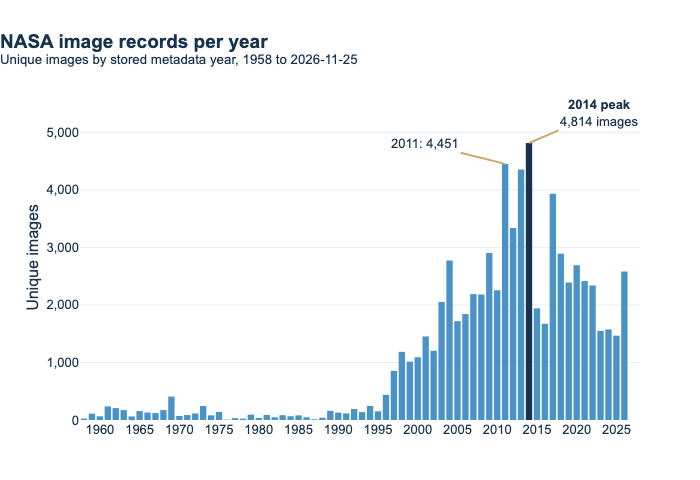

In [8]:
modern = annual_counts[annual_counts["year"] >= 1958]
fig_trend = go.Figure(go.Bar(
    x=modern["year"], y=modern["unique_images"],
    marker_color=[NAVY if year == peak_year else BLUE for year in modern["year"]],
    hovertemplate="<b>%{x}</b><br>%{y:,} images<extra></extra>",
))
fig_trend.add_annotation(x=peak_year, y=peak_images, text=f"<b>{peak_year} peak</b><br>{peak_images:,} images",
                         showarrow=True, arrowhead=0, arrowcolor=GOLD, ax=70, ay=-30, bgcolor="white")
runner_up = top_years.iloc[1]
fig_trend.add_annotation(x=int(runner_up["year"]), y=int(runner_up["unique_images"]),
                         text=f"{int(runner_up['year'])}: {int(runner_up['unique_images']):,}",
                         showarrow=True, arrowhead=0, arrowcolor=GOLD, ax=-80, ay=-20, bgcolor="white")
fig_trend.update_layout(
    title=f"<b>NASA image records per year</b><br><sup>Unique images by stored metadata year, 1958 to {as_of_date}</sup>",
    height=480, showlegend=False, bargap=0.2,
)
fig_trend.update_xaxes(dtick=5, showgrid=False, title=None)
fig_trend.update_yaxes(tickformat=",d", title="Unique images")
show_and_save(fig_trend, "insight1_historical_peak.png")

### 1.2 Which centers changed between 2013 and 2014?

The peak could come from every center growing a little, or from one center growing a lot. Let's compare each center's records in the two years.

In [9]:
center_years = sql(f"""
    SELECT COALESCE(NULLIF(BTRIM(r.center), ''), 'Unknown') AS center,
           COUNT(*) FILTER (WHERE EXTRACT(YEAR FROM r.date) = 2013) AS y2013,
           COUNT(*) FILTER (WHERE EXTRACT(YEAR FROM r.date) = 2014) AS y2014
    FROM nasa_records AS r
    WHERE {SCOPE} AND EXTRACT(YEAR FROM r.date) IN (2013, 2014)
    GROUP BY 1
    ORDER BY y2014 DESC
""")
center_years["change"] = center_years["y2014"] - center_years["y2013"]
total_2014 = int(center_years["y2014"].sum())
center_years["share_2014"] = center_years["y2014"] / total_2014 * 100
assert total_2014 == int(annual_counts.set_index("year").loc[2014, "unique_images"])
show_table(center_years.head(8).rename(columns={"center": "Center", "y2013": "2013", "y2014": "2014",
                                                "change": "Change", "share_2014": "Share of 2014"}),
           {"2013": "{:,.0f}", "2014": "{:,.0f}", "Change": "{:+,.0f}", "Share of 2014": "{:.1f}%"})

# KSC's own busiest year, so we don't overstate what 2014 meant for KSC.
ksc_annual = sql(f"""
    SELECT EXTRACT(YEAR FROM r.date)::integer AS year, COUNT(*) AS images
    FROM nasa_records AS r WHERE {SCOPE} AND {HISTORICAL} AND r.center = 'KSC'
    GROUP BY 1 ORDER BY images DESC LIMIT 3
""")
show_table(ksc_annual.rename(columns={"year": "KSC's busiest years", "images": "Images"}), {"Images": "{:,.0f}"})

Center,2013,2014,Change,Share of 2014
KSC,"1,647","2,396",+749,49.8%
JSC,"1,410",963,-447,20.0%
JPL,"1,037",944,-93,19.6%
HQ,232,505,+273,10.5%
GSFC,0,4,+4,0.1%
AFRC,1,1,+0,0.0%
MSFC,8,1,-7,0.0%
ARC,1,0,-1,0.0%


KSC's busiest years,Images
2011,"2,583"
2014,"2,396"
2013,"1,647"


### 1.3 A closer look: KSC's Earth-topic records and five missions

KSC grew the most, and most of its growth sits in records that matched the **Earth** search topic. These are keyword-search matches, not necessarily photos *of* Earth.

While exploring those records we noticed five mission names coming up again and again. For each mission we search the **title and keywords** with an explicit pattern (`dashboard/analysis_rules.py`):

In [10]:
show_table(pd.DataFrame({"Mission": list(rules.PEAK_MISSIONS), "Pattern (PostgreSQL, case-insensitive)":
                         list(rules.PEAK_MISSIONS.values())}))

Mission,"Pattern (PostgreSQL, case-insensitive)"
Orion / EFT-1,\morion\M|\meft-1\M|exploration flight test
Morpheus / ALHAT,\mmorpheus\M|\malhat\M
OCO-2,\moco-2\M|orbiting carbon observatory
TDRS,\mtdrs|tracking and data relay
SMAP,\msmap\M|soil moisture active passive


Now let's compare the mission-related records between 2013 and 2014. An image can mention two missions, so the "any mission" column is a **deduplicated union**: each image counts once.

In [11]:
mission_params = {f"m{i}": pattern for i, pattern in enumerate(rules.PEAK_MISSIONS.values())}
flags = ", ".join(f"(text_value ~* :m{i}) AS m{i}" for i in range(len(mission_params)))
mission_counts = ", ".join(f"COUNT(*) FILTER (WHERE m{i}) AS m{i}" for i in range(len(mission_params)))
any_mission = " OR ".join(f"m{i}" for i in range(len(mission_params)))
peak_breakdown = sql(f"""
    WITH subset AS (
        SELECT EXTRACT(YEAR FROM r.date)::integer AS year,
               r.title || ' | ' || COALESCE((SELECT string_agg(k, ' | ')
                                             FROM jsonb_array_elements_text(r.keywords) AS k), '') AS text_value
        FROM nasa_records AS r
        WHERE {SCOPE} AND r.center = 'KSC' AND EXTRACT(YEAR FROM r.date) IN (2013, 2014)
          AND EXISTS (SELECT 1 FROM nasa_search_matches AS m
                      WHERE m.source_api = r.source_api AND m.source_id = r.source_id
                        AND m.search_keyword = 'earth')
    ), flagged AS (SELECT year, {flags} FROM subset)
    SELECT year, COUNT(*) AS total, {mission_counts},
           COUNT(*) FILTER (WHERE {any_mission}) AS any_mission
    FROM flagged GROUP BY year ORDER BY year
""", **mission_params)
peak_breakdown = peak_breakdown.rename(columns={f"m{i}": name for i, name in enumerate(rules.PEAK_MISSIONS)})
peak_breakdown["other"] = peak_breakdown["total"] - peak_breakdown["any_mission"]
peak_breakdown["mission_share"] = peak_breakdown["any_mission"] / peak_breakdown["total"] * 100

# The union can never be smaller than the biggest mission or larger than their sum.
missions = list(rules.PEAK_MISSIONS)
for _, row in peak_breakdown.iterrows():
    assert row[missions].max() <= row["any_mission"] <= row[missions].sum()

show_table(peak_breakdown.set_index("year").T.reset_index().rename(columns={"index": "Measure"}),
           {2013: fmt_number, 2014: fmt_number})

Measure,2013,2014
total,894,"1,481"
Orion / EFT-1,202,353
Morpheus / ALHAT,93,193
OCO-2,22,108
TDRS,8,96
SMAP,0,80
any_mission,325,830
other,569,651
mission_share,36.35,56.04


Here is the growth broken into the mission-related part and everything else. This is a **descriptive decomposition** of what changed, not a causal estimate.

In [12]:
b13, b14 = peak_breakdown.set_index("year").loc[2013], peak_breakdown.set_index("year").loc[2014]
subset_growth = int(b14["total"] - b13["total"])
mission_growth = int(b14["any_mission"] - b13["any_mission"])
other_growth = int(b14["other"] - b13["other"])
assert mission_growth + other_growth == subset_growth
decomposition = pd.DataFrame({
    "Measure": ["KSC Earth-topic records", "Mention at least one of the five missions", "Other records",
                "Mission-related share (percentage points)"],
    "2013": [b13["total"], b13["any_mission"], b13["other"], b13["mission_share"]],
    "2014": [b14["total"], b14["any_mission"], b14["other"], b14["mission_share"]],
    "Change": [subset_growth, mission_growth, other_growth, b14["mission_share"] - b13["mission_share"]],
})
show_table(decomposition, {"2013": fmt_number, "2014": fmt_number,
                           "Change": lambda v: ("+" if v > 0 else "") + fmt_number(v)})
print(f"Total growth: {subset_growth:+,} ({subset_growth / b13['total'] * 100:+.1f}%). "
      f"Mission-related growth: {mission_growth:+,} = {mission_growth / subset_growth * 100:.1f}% of the net increase.")

Measure,2013,2014,Change
KSC Earth-topic records,894,"1,481",+587
Mention at least one of the five missions,325,830,+505
Other records,569,651,+82
Mission-related share (percentage points),36.35,56.04,+19.69


Total growth: +587 (+65.7%). Mission-related growth: +505 = 86.0% of the net increase.


**Figure B** puts the decomposition next to the mission-level counts. The left panel stacks mission-related and other records; the right panel shows each mission on its own (an image naming two missions appears in both bars there).

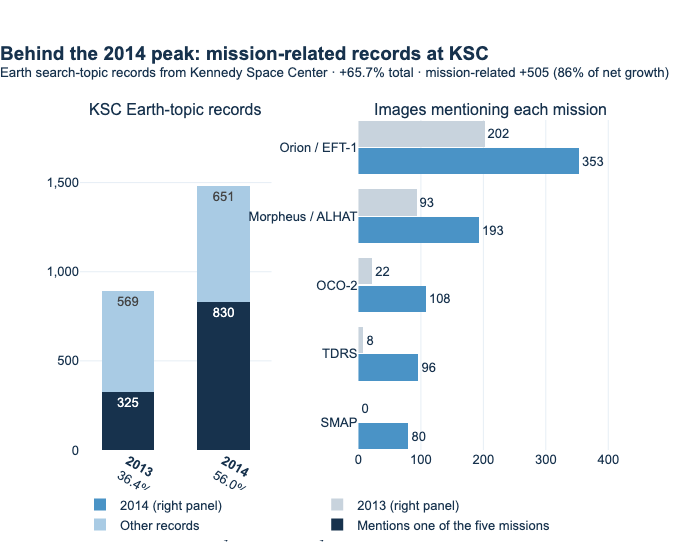

In [13]:
fig_missions = make_subplots(
    rows=1, cols=2, column_widths=[0.42, 0.58], horizontal_spacing=0.16,
    subplot_titles=("KSC Earth-topic records", "Images mentioning each mission"))
years = peak_breakdown["year"].astype(str)
# Left panel: mission-related records with the other records stacked on top (via "base").
fig_missions.add_bar(x=years, y=peak_breakdown["any_mission"], name="Mentions one of the five missions",
                     marker_color=NAVY, text=peak_breakdown["any_mission"], texttemplate="%{y:,}",
                     textposition="inside", insidetextfont=dict(color="white"), width=0.55, row=1, col=1)
fig_missions.add_bar(x=years, y=peak_breakdown["other"], name="Other records",
                     marker_color=LIGHT_BLUE, text=peak_breakdown["other"], texttemplate="%{y:,}",
                     textposition="inside", width=0.55, row=1, col=1)
# Right panel: each mission's two years side by side, placed at explicit positions
# (the figure is in stack mode for the left panel, so we offset the bars ourselves).
for (_, row), color, shift in zip(peak_breakdown.iterrows(), [GREY, BLUE], [-0.2, 0.2]):
    year = int(row["year"])
    fig_missions.add_bar(y=[i + shift for i in range(len(missions))], x=[int(row[m]) for m in missions],
                         orientation="h", width=0.38, marker_color=color, name=f"{year} (right panel)",
                         text=[int(row[m]) for m in missions], textposition="outside", cliponaxis=False,
                         row=1, col=2)
fig_missions.update_layout(
    title="<b>Behind the 2014 peak: mission-related records at KSC</b>"
          f"<br><sup>Earth search-topic records from Kennedy Space Center · {subset_growth / b13['total'] * 100:+.1f}% total · "
          f"mission-related +{mission_growth:,} ({mission_growth / subset_growth * 100:.0f}% of net growth)</sup>",
    barmode="stack", height=560, legend=dict(orientation="h", y=-0.12, x=0),
    margin=dict(t=120, b=110),
)
fig_missions.update_xaxes(type="category", showgrid=False, range=[-0.5, len(years) - 0.5],
                          tickvals=list(years), ticktext=[f"<b>{y}</b><br>{share:.1f}% mission-related" for y, share
                                                          in zip(years, peak_breakdown["mission_share"])], row=1, col=1)
fig_missions.update_yaxes(tickformat=",d", range=[0, b14["total"] * 1.25], row=1, col=1)
fig_missions.update_yaxes(autorange="reversed", showgrid=False, tickvals=list(range(len(missions))),
                          ticktext=missions, row=1, col=2)
fig_missions.update_xaxes(range=[0, peak_breakdown[missions].max().max() * 1.2], row=1, col=2)
show_and_save(fig_missions, "insight1_mission_comparison.png", width=1300)

### 1.4 What these records look like

Real images from the 2014 KSC Earth-topic records, chosen by a fixed rule: the earliest record whose title names the mission (ID-only titles skipped).

In [14]:
example_rows = []
for mission in ["Orion / EFT-1", "OCO-2", "Morpheus / ALHAT"]:
    example_rows.append(sql(f"""
        SELECT r.source_id, r.title, r.date::text AS date, r.image_url, r.page_url, r.credit, :mission AS mission
        FROM nasa_records AS r
        WHERE {SCOPE} AND r.center = 'KSC' AND EXTRACT(YEAR FROM r.date) = 2014
          AND EXISTS (SELECT 1 FROM nasa_search_matches AS m
                      WHERE m.source_id = r.source_id AND m.source_api = r.source_api AND m.search_keyword = 'earth')
          AND r.title ~* :pattern AND r.title !~ :id_only AND r.image_url LIKE '%~thumb.jpg'
        ORDER BY r.date, r.source_id LIMIT 1
    """, mission=mission, pattern=rules.PEAK_MISSIONS[mission], id_only=rules.ID_ONLY_TITLE))
peak_examples = pd.concat(example_rows, ignore_index=True)
image_cards(peak_examples, "mission")

### 1.5 NASA historical context (external sources)

These events come from NASA's official pages, not from our database. They help explain *why* these mission names appear in KSC's 2014 records:

| Event | Date | Official source |
|---|---|---|
| TDRS-L launch from Cape Canaveral (Atlas V) | Jan 23, 2014 | [nasa.gov](https://www.nasa.gov/image-article/tracking-data-relay-satellite-launch-lights-up-night-sky/) |
| GPM launch (NASA/JAXA, from Tanegashima, Japan) | Feb 27, 2014 | [gpm.nasa.gov](https://gpm.nasa.gov/resources/faq/when-did-gpm-launch) |
| OCO-2 launch from Vandenberg (Delta II) | Jul 2, 2014 | [nasa.gov](https://www.nasa.gov/news-release/nasa-launches-new-carbon-sensing-mission-to-monitor-earths-breathing-2/) |
| MAVEN enters Mars orbit | Sep 21, 2014 | [science.nasa.gov](https://science.nasa.gov/mission/maven/) |
| Morpheus free flights at KSC's Shuttle Landing Facility (13 flights, 6 with ALHAT) | Dec 2013 – Dec 15, 2014 | [nasa.gov](https://www.nasa.gov/technology/morpheus-team-completes-alhat-system-tests-on-prototype-lander/) |
| Orion Exploration Flight Test-1 (Delta IV Heavy, Cape Canaveral) | Dec 5, 2014 | [nasa.gov](https://www.nasa.gov/mission/exploration-flight-test-1/) |
| SMAP launch from Vandenberg | Jan 31, 2015 | [nasa.gov LSP archive](https://www.nasa.gov/reference/lsp-primary-launches-archive/) |

SMAP launched in 2015, so its 80 records in 2014 show **prelaunch preparation**. GPM and MAVEN are real 2014 milestones, but our data does not link them to the KSC Earth growth, so we don't use them as an explanation.

**Budget context (kept separate from the metadata analysis).** NASA's FY2014 operating plan funded Earth Science at **$1,824.9 million** and Planetary Science at **$1,343.4 million** ([FY2014 operating plan, PDF](https://www.nasa.gov/wp-content/uploads/2018/02/fy-2014-nasa-operating-plan-june-2014.pdf)). This is fiscal-year funding, a different measure and period from calendar-year image records, so we don't compare the two directly.

### 1.6 Key Findings

In [15]:
ksc_row = center_years.set_index("center").loc["KSC"]
risers = center_years[center_years["change"] > 0].nlargest(2, "change")
fallers = center_years[center_years["change"] < 0].nsmallest(2, "change")
display(Markdown(f"""
- **{peak_year} is the busiest year in our archive ({peak_images:,} images)**, just ahead of {int(runner_up['year'])} ({int(runner_up['unique_images']):,}). Kennedy Space Center supplied **{ksc_row['share_2014']:.1f}%** of 2014's records, although KSC's own busiest year was {int(ksc_annual.loc[0, 'year'])} ({int(ksc_annual.loc[0, 'images']):,}).
- The jump was not shared by every center: {", ".join(f"**{r.center}** {r.change:+,}" for r in risers.itertuples())}, while {", ".join(f"**{r.center}** {r.change:+,}" for r in fallers.itertuples())}.
- Inside KSC's Earth-topic records ({int(b13['total']):,} → {int(b14['total']):,}, **{subset_growth / b13['total'] * 100:+.1f}%**), images mentioning Orion/EFT-1, Morpheus/ALHAT, OCO-2, TDRS, or SMAP grew from {int(b13['any_mission']):,} to {int(b14['any_mission']):,}. **The increase in records mentioning these five missions accounted for approximately {mission_growth / subset_growth * 100:.0f}% of the net growth in this KSC Earth-topic subset**, and their share rose from {b13['mission_share']:.2f}% to {b14['mission_share']:.2f}%.
"""))


- **2014 is the busiest year in our archive (4,814 images)**, just ahead of 2011 (4,451). Kennedy Space Center supplied **49.8%** of 2014's records, although KSC's own busiest year was 2011 (2,583).
- The jump was not shared by every center: **KSC** +749, **HQ** +273, while **JSC** -447, **JPL** -93.
- Inside KSC's Earth-topic records (894 → 1,481, **+65.7%**), images mentioning Orion/EFT-1, Morpheus/ALHAT, OCO-2, TDRS, or SMAP grew from 325 to 830. **The increase in records mentioning these five missions accounted for approximately 86% of the net growth in this KSC Earth-topic subset**, and their share rose from 36.35% to 56.04%.


*How to read this:* the five missions were picked after looking at the data, so the 86%-style figure describes how the archive's composition changed. It does not prove that these missions caused NASA's overall image peak. A mission "mention" means the name appears in a title or keyword.

---
## Section 2 — Beyond Planet Photos: NASA Centers & Image Content

**Research question:** *Do different NASA centers contribute different kinds of image records?*

Knowing which center has the most pictures is only the start. We want to know *what* each center documents.

### 2.1 Center rankings

We'll first check which NASA centers contributed the most image records.

In [16]:
center_ranking = sql(f"""
    SELECT COALESCE(NULLIF(BTRIM(r.center), ''), 'Unknown') AS center, COUNT(*) AS images,
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS share
    FROM nasa_records AS r WHERE {SCOPE}
    GROUP BY 1 ORDER BY images DESC, center
""")
top_centers = center_ranking.head(10)
show_table(top_centers.rename(columns={"center": "Center", "images": "Unique images", "share": "Share"}),
           {"Unique images": "{:,.0f}", "Share": "{:.2f}%"})
focus = ["KSC", "JPL", "JSC"]
top_three_share = top_centers.loc[top_centers["center"].isin(focus), "share"].sum()
print(f"KSC + JPL + JSC = {top_three_share:.1f}% of all records")

Center,Unique images,Share
KSC,"26,920",36.41%
JPL,"20,858",28.21%
JSC,"12,840",17.37%
HQ,"6,266",8.47%
GSFC,"2,227",3.01%
MSFC,"2,150",2.91%
MAF,889,1.20%
ARC,700,0.95%
GRC,419,0.57%
AFRC,341,0.46%


KSC + JPL + JSC = 82.0% of all records


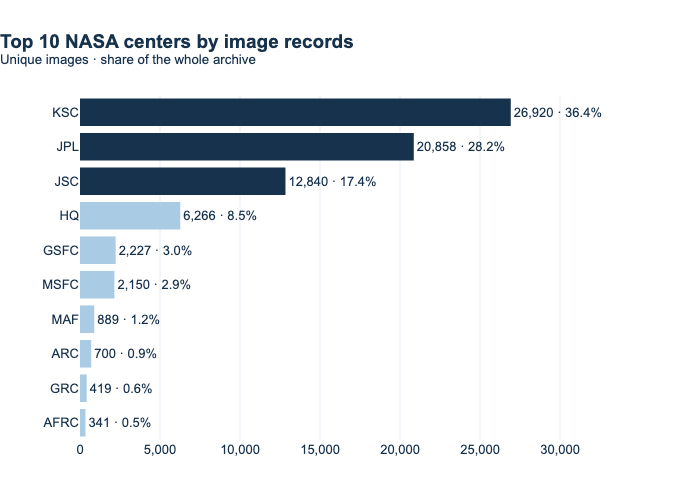

In [17]:
fig_centers = go.Figure(go.Bar(
    x=top_centers["images"], y=top_centers["center"], orientation="h",
    marker_color=[NAVY if c in focus else LIGHT_BLUE for c in top_centers["center"]],
    text=[f"{n:,} · {s:.1f}%" for n, s in zip(top_centers["images"], top_centers["share"])],
    textposition="outside", cliponaxis=False,
))
fig_centers.update_layout(title="<b>Top 10 NASA centers by image records</b><br><sup>Unique images · share of the whole archive</sup>",
                          height=500, showlegend=False)
fig_centers.update_yaxes(autorange="reversed", showgrid=False, title=None)
fig_centers.update_xaxes(tickformat=",d", range=[0, top_centers["images"].max() * 1.3], title=None)
show_and_save(fig_centers, "insight2_nasa_centers.png")

### 2.2 Our first title-keyword experiment, re-run

Earlier we flagged titles containing words like *launch, briefing, crew, processing, testing, splashdown, installation*. Here is that first word list (word-start matching), re-run on the current database:

In [18]:
first_rule = sql(f"""
    SELECT r.center, COUNT(*) AS records,
           COUNT(*) FILTER (WHERE r.title ~* :rule) AS matches
    FROM nasa_records AS r WHERE {SCOPE} AND r.center = ANY(:centers)
    GROUP BY 1 ORDER BY records DESC
""", rule=rules.OPERATIONS_TITLE_V1, centers=focus)
first_rule["match_rate"] = first_rule["matches"] / first_rule["records"] * 100
show_table(first_rule.rename(columns={"center": "Center", "records": "Records", "matches": "Title matches",
                                      "match_rate": "Match rate"}),
           {"Records": "{:,.0f}", "Title matches": "{:,.0f}", "Match rate": "{:.2f}%"})

Center,Records,Title matches,Match rate
KSC,"26,920","3,778",14.03%
JPL,"20,858",189,0.91%
JSC,"12,840","4,855",37.81%


At first glance JSC looks the most "operational". But reading the matched and unmatched titles turned up two problems:

1. **Many titles are just an archive ID**, such as `KSC-2011-7368` or `iss068e054895`. A title rule can't say anything about those.
2. **"Crew" is a false friend at JSC.** Thousands of titles read *"Earth Observations taken by the Expedition 38 crew"*. Those are photographs **of Earth**, taken by astronauts.

Let's measure both.

In [19]:
title_checks = sql(f"""
    SELECT r.center, COUNT(*) AS records,
           COUNT(*) FILTER (WHERE r.title = r.source_id OR r.title ~ :id_only) AS id_only_titles,
           COUNT(*) FILTER (WHERE r.title ~* :earth) AS earth_observation_titles,
           COUNT(*) FILTER (WHERE r.title ~* :earth AND r.title ~* :rule) AS earth_titles_matching_first_rule,
           COUNT(*) FILTER (WHERE r.source_id LIKE 'PIA%') AS photojournal_ids
    FROM nasa_records AS r WHERE {SCOPE} AND r.center = ANY(:centers)
    GROUP BY 1 ORDER BY records DESC
""", id_only=rules.ID_ONLY_TITLE, earth=rules.EARTH_OBSERVATION_TITLE, rule=rules.OPERATIONS_TITLE_V1, centers=focus)
for column in ["id_only_titles", "earth_observation_titles", "photojournal_ids"]:
    title_checks[column + "_pct"] = title_checks[column] / title_checks["records"] * 100
show_table(title_checks.rename(columns={
    "center": "Center", "records": "Records", "id_only_titles": "ID-only titles", "id_only_titles_pct": "ID-only %",
    "earth_observation_titles": "Crew Earth-observation titles", "earth_observation_titles_pct": "Earth-obs %",
    "earth_titles_matching_first_rule": "…of which matched the first rule", "photojournal_ids": "PIA (Photojournal) IDs",
    "photojournal_ids_pct": "PIA %"}),
    {c: "{:,.0f}" for c in ["Records", "ID-only titles", "Crew Earth-observation titles",
                             "…of which matched the first rule", "PIA (Photojournal) IDs"]}
    | {c: "{:.1f}%" for c in ["ID-only %", "Earth-obs %", "PIA %"]})

Center,Records,ID-only titles,Crew Earth-observation titles,…of which matched the first rule,PIA (Photojournal) IDs,ID-only %,Earth-obs %,PIA %
KSC,"26,920","16,445",0,0,0,61.1%,0.0%,0.0%
JPL,"20,858",22,1,0,"20,855",0.1%,0.0%,100.0%
JSC,"12,840","1,533","3,721","2,349",0,11.9%,29.0%,0.0%


### 2.3 A refined, transparent content grouping

We refined the rule in three ways, all documented in `dashboard/analysis_rules.py`:

1. **ID-only titles** get their own group instead of being counted as "not operational".
2. **Crew Earth photography** (`earth observ…`) is checked before the operations words.
3. The operations word list adds words we saw being missed (for example *liftoff, rollout, offload, arrival, mate, EVA, undock, technicians, visit*), matched as whole words.

Every record lands in exactly one of four groups.

In [20]:
operations, earth_group, other_group, id_only_group = rules.CONTENT_GROUPS
content = sql(f"""
    SELECT r.center,
           CASE WHEN r.title = r.source_id OR r.title ~ :id_only THEN :g_id
                WHEN r.title ~* :earth THEN :g_earth
                WHEN r.title ~* :operations THEN :g_ops
                ELSE :g_other END AS content_group,
           COUNT(*) AS images
    FROM nasa_records AS r WHERE {SCOPE} AND r.center = ANY(:centers)
    GROUP BY 1, 2
""", id_only=rules.ID_ONLY_TITLE, earth=rules.EARTH_OBSERVATION_TITLE, operations=rules.OPERATIONS_TITLE,
    g_id=id_only_group, g_earth=earth_group, g_ops=operations, g_other=other_group, centers=focus)
content_table = content.pivot_table(index="center", columns="content_group", values="images", fill_value=0)
content_table = content_table.reindex(index=focus, columns=rules.CONTENT_GROUPS, fill_value=0).astype(int)
assert (content_table.sum(axis=1) == first_rule.set_index("center").loc[focus, "records"]).all()
content_share = content_table.div(content_table.sum(axis=1), axis=0) * 100
descriptive = content_table.drop(columns=id_only_group).sum(axis=1)
ops_of_descriptive = content_table[operations] / descriptive * 100
show_table(content_share.round(2).assign(**{"Operations share of descriptive titles": ops_of_descriptive.round(2)})
           .reset_index().rename(columns={"center": "Center"}),
           {c: "{:.1f}%" for c in rules.CONTENT_GROUPS + ["Operations share of descriptive titles"]})

Center,"Operations, people & engineering",Earth photography by crews,Other descriptive title,ID-only title,Operations share of descriptive titles
KSC,26.6%,0.0%,12.4%,61.1%,68.2%
JPL,1.9%,0.0%,98.0%,0.1%,1.9%
JSC,22.9%,29.0%,36.2%,11.9%,26.0%


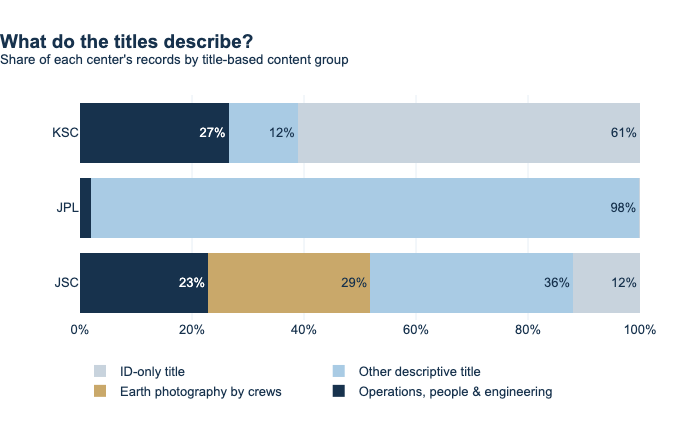

In [21]:
colors = {operations: NAVY, earth_group: GOLD, other_group: LIGHT_BLUE, id_only_group: GREY}
fig_content = go.Figure()
for group in rules.CONTENT_GROUPS:
    fig_content.add_bar(
        y=focus, x=content_share.loc[focus, group], orientation="h", name=group, marker_color=colors[group],
        text=[f"{v:.0f}%" if v >= 5 else "" for v in content_share.loc[focus, group]], textposition="inside",
        insidetextfont=dict(color="white" if group == operations else NAVY),
    )
fig_content.update_layout(
    title="<b>What do the titles describe?</b><br><sup>Share of each center's records by title-based content group</sup>",
    barmode="stack", height=430, legend=dict(orientation="h", y=-0.16, x=0), margin=dict(b=110),
)
fig_content.update_xaxes(range=[0, 100], ticksuffix="%")
fig_content.update_yaxes(autorange="reversed", showgrid=False)
show_and_save(fig_content, "insight2_content_patterns.png")

### 2.4 Manual review of a fixed sample

To check the refined rule, we drew a **reproducible sample**: for each of KSC, JSC, and JPL, 20 descriptive titles the rule flags as operations/people/engineering, and 20 it doesn't. The order is fixed with `md5('nasa-review-v2:' || source_id)`, so re-running the cell returns the same 120 titles.

We read each title (and, for a few unclear ones, the description) and labeled it:

- **For flagged titles:** `correct`, `false positive`, or `unclear`.
- **For unflagged titles:** `correctly excluded`, `missed` (it really shows operations, people, or engineering), or `unclear`.

The labels below are our judgment calls. They were drafted with AI assistance during this analysis and listed in full, so anyone can audit or change them.

In [22]:
review_sample = []
for center in focus:
    for flagged in (True, False):
        condition = "(r.title ~* :ops AND r.title !~* :earth)" if flagged else "NOT (r.title ~* :ops AND r.title !~* :earth)"
        rows = sql(f"""
            SELECT r.center, r.source_id, r.title
            FROM nasa_records AS r
            WHERE {SCOPE} AND r.center = :center
              AND NOT (r.title = r.source_id OR r.title ~ :id_only) AND {condition}
            ORDER BY md5('nasa-review-v2:' || r.source_id)
            LIMIT 20
        """, center=center, ops=rules.OPERATIONS_TITLE, earth=rules.EARTH_OBSERVATION_TITLE, id_only=rules.ID_ONLY_TITLE)
        rows["flagged"] = flagged
        review_sample.append(rows)
review_sample = pd.concat(review_sample, ignore_index=True)

# Our labels. Unlisted flagged titles were judged "correct"; unlisted unflagged ones "correctly excluded".
REVIEW_EXCEPTIONS = {
    # KSC titles the rule missed: hardware, processing, simulations, facilities, and people.
    "KSC-20260717-PH-JMT01_0002": "missed", "KSC-20200702-PH-ILW01_0082": "missed",
    "KSC-20210315-PH-KLS01_0032": "missed", "KSC-20190322-PH_BOE01_0019": "missed",
    "KSC-20260114-PH-AJN01_0035": "missed", "KSC-20251116-PH-SPX01_0004": "missed",
    "KSC-20240205-PH-SPX02_0004": "missed", "KSC-20160918-PH_CAB01_0061": "missed",
    "KSC-20190322-PH_BOE01_0005": "missed", "KSC-20240802-PH-KLS01_0009": "missed",
    "KSC-20210720-PH-RNB01_0115": "missed", "KSC-20181111-PH_BOE01_0006": "missed",
    "KSC-20230421-PH-KLS01_0021": "missed", "KSC-20250507-PH-KLS01_0136": "missed",
    "KSC-JohnGlenn-0005": "missed", "KSC-20220606-PH-KLS01_0015_": "missed",
    "KSC-20191122-PH-KLS01_0018": "missed",
    # JSC: a missile launch photographed from the ISS is Earth imagery, not a NASA operation.
    "iss037e009296": "false positive",
    "iss026e020069": "missed", "iss016e009791": "missed", "iss052e004198": "missed",
    "sts056-92-0028": "missed", "iss028e015564": "missed", "iss038e046387": "missed",
    # JPL: a Mercury flyby ("countdown") is science; two illustrations are unclear.
    "PIA10170": "false positive", "PIA24496": "unclear", "PIA05489": "unclear",
    "PIA25260": "missed", "PIA15277": "missed", "PIA11192": "unclear", "PIA26244": "unclear",
}
assert set(REVIEW_EXCEPTIONS) <= set(review_sample["source_id"]), "The fixed sample changed; re-check the labels."
review_sample["label"] = [
    REVIEW_EXCEPTIONS.get(sid, "correct" if flagged else "correctly excluded")
    for sid, flagged in zip(review_sample["source_id"], review_sample["flagged"])
]
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 110):
    display(review_sample.assign(title=review_sample["title"].str.slice(0, 105))
            .rename(columns={"center": "Center", "source_id": "NASA ID", "title": "Title",
                             "flagged": "Flagged by rule", "label": "Our label"}))

,Center,NASA ID,Title,Flagged by rule,Our label
0,KSC,KSC-20180812-PH_GEB01_0013,Dr. Parker Watches Parker Solar Probe Liftoff,True,correct
1,KSC,KSC-2014-1819,OCO-2 Booster Offload,True,correct
2,KSC,KSC-20260621-PH-SNW01_0002,Roman Space Telescope Transport to PHSF,True,correct
3,KSC,KSC-20161103-PH_SWW01_0009,Orion Underway Recovery Test 5 (URT-5),True,correct
4,KSC,VAFB-20180227-PH_RKB01_0032,InSight Atlas V Centaur Stage Prep for Transport,True,correct
5,KSC,KSC-20190710-PH_GEB01_0182,Artemis-2 Heat Shield Arrival,True,correct
6,KSC,KSC-20220317-PH-KLS02_0002,Artemis I WDR Rollout - VAB Doors Open,True,correct
7,KSC,KSC-03pd1718,"KENNEDY SPACE CENTER, FLA. - On Launch Pad 17-A, Cape Canaveral Air Force Station, the Mars Exploration R",True,correct
8,KSC,KSC-03pd2885,"VANDENBERG AFB, CALIF. - Viewed from inside, the second stage of the Delta II launch vehicle for the Grav",True,correct
9,KSC,KSC-20260320-PH-JBS01_0122,Artemis II Rollout for Launch,True,correct


Summarizing the review:

In [23]:
review_summary = (review_sample.groupby(["center", "flagged"])["label"].value_counts()
                  .unstack(fill_value=0).reindex(columns=["correct", "false positive", "unclear", "missed",
                                                          "correctly excluded"], fill_value=0))
review_summary = review_summary.reset_index().rename(columns={"center": "Center", "flagged": "Flagged by rule"})
show_table(review_summary)
precision = review_sample[review_sample["flagged"]].groupby("center")["label"].apply(lambda s: (s == "correct").mean() * 100)
missed = review_sample[~review_sample["flagged"]].groupby("center")["label"].apply(lambda s: (s == "missed").mean() * 100)
print("Flagged titles judged correct:", ", ".join(f"{c} {precision[c]:.0f}%" for c in focus))
print("Unflagged titles that were actually operations/people/engineering:", ", ".join(f"{c} {missed[c]:.0f}%" for c in focus))

Center,Flagged by rule,correct,false positive,unclear,missed,correctly excluded
JPL,False,0,0,2,2,16
JPL,True,17,1,2,0,0
JSC,False,0,0,0,6,14
JSC,True,19,1,0,0,0
KSC,False,0,0,0,17,3
KSC,True,20,0,0,0,0


Flagged titles judged correct: KSC 100%, JPL 85%, JSC 95%
Unflagged titles that were actually operations/people/engineering: KSC 85%, JPL 10%, JSC 30%


**What the review tells us.** When the rule flags a title, it is usually right. When it doesn't, KSC titles are often still about operations (simulations, hardware moves, facility work, people), so the KSC figures are a **lower bound**. At JPL, the unflagged titles were mostly planetary science imagery, with a few engineering and technology photos. Because a title without operations words is *not* proof of a science image, we never call JPL's non-matches "scientific photographs".

### 2.5 Three kinds of archive content

One real record from each center illustrates the difference:

In [24]:
examples = []
for label, center, pattern, excluded in [
    ("KSC · launch processing", "KSC", r"encapsulat|fairing|rollout", "$^"),
    ("JSC · crew Earth photography", "JSC", r"aurora|airglow", "$^"),
    ("JPL · Photojournal Mars image", "JPL", r"dunes", rules.OPERATIONS_TITLE),
]:
    examples.append(sql(f"""
        SELECT r.source_id, r.title, r.date::text AS date, r.image_url, r.page_url, r.credit, :label AS label
        FROM nasa_records AS r
        WHERE {SCOPE} AND {HISTORICAL} AND r.center = :center AND r.title ~* :pattern
          AND r.title !~* :excluded AND r.title !~ :id_only AND r.image_url LIKE '%~thumb.jpg'
          AND (:center <> 'JPL' OR r.source_id LIKE 'PIA%')
        ORDER BY r.date DESC, r.source_id LIMIT 1
    """, label=label, center=center, pattern=pattern, excluded=excluded, id_only=rules.ID_ONLY_TITLE))
image_cards(pd.concat(examples, ignore_index=True), "label")

### 2.6 Key Findings

In [25]:
display(Markdown(f"""
- **KSC, JPL, and JSC supply {top_three_share:.1f}% of all records**, with KSC the largest ({int(top_centers.loc[0, 'images']):,}).
- They document very different things. **{ops_of_descriptive['KSC']:.0f}%** of KSC's descriptive titles mention launches, processing, crews, tests, or events. **{content_share.loc['JSC', earth_group]:.0f}%** of JSC records are titled as crew Earth observations. At JPL only **{content_share.loc['JPL', operations]:.1f}%** of titles use these words, and **{title_checks.set_index('center').loc['JPL', 'photojournal_ids_pct']:.2f}%** of its records carry Photojournal (PIA) IDs.
- Our first keyword list made JSC look the most operational ({first_rule.set_index('center').loc['JSC', 'match_rate']:.1f}% vs. {first_rule.set_index('center').loc['KSC', 'match_rate']:.1f}% for KSC), but **{title_checks.set_index('center').loc['JSC', 'earth_titles_matching_first_rule']:,}** of JSC's matches were crew Earth-observation titles, and **{title_checks.set_index('center').loc['KSC', 'id_only_titles_pct']:.0f}%** of KSC's titles are only an ID. These are title-metadata rates, not validated content labels.
- This mix is exactly why the dashboard has two views: **Planet Gallery = Curated Discovery** for planetary imagery, and **Archive Search = Comprehensive Retrieval**, which keeps launches, engineering, astronauts, and operations records that are valuable even when they aren't planet photos.
"""))


- **KSC, JPL, and JSC supply 82.0% of all records**, with KSC the largest (26,920).
- They document very different things. **68%** of KSC's descriptive titles mention launches, processing, crews, tests, or events. **29%** of JSC records are titled as crew Earth observations. At JPL only **1.9%** of titles use these words, and **99.99%** of its records carry Photojournal (PIA) IDs.
- Our first keyword list made JSC look the most operational (37.8% vs. 14.0% for KSC), but **2,349** of JSC's matches were crew Earth-observation titles, and **61%** of KSC's titles are only an ID. These are title-metadata rates, not validated content labels.
- This mix is exactly why the dashboard has two views: **Planet Gallery = Curated Discovery** for planetary imagery, and **Archive Search = Comprehensive Retrieval**, which keeps launches, engineering, astronauts, and operations records that are valuable even when they aren't planet photos.


---
## Section 3 — Missions, Sources & Locations

**Research question:** *Which NASA missions, institutions, sources, and locations appear most often in our archived image metadata?*

Credit, Location, and Keywords are optional fields, so every ranking here describes only the records that have that field (see the completeness table in Section 4).

### 3.1 Cleaning the keywords

Keywords are stored as a JSON array, but many array items are actually comma-separated phrases such as `"orion, eft-1, delta iv, flight test, exploration"`. We parse the array, split each item on commas, lowercase it, collapse spaces, and count **distinct images** per keyword. The raw values in PostgreSQL stay unchanged; this happens only inside the query.

First, how common are comma-packed items?

In [26]:
keyword_shape = sql(f"""
    SELECT COUNT(*) FILTER (WHERE jsonb_array_length(r.keywords) > 0) AS images_with_keyword_items,
           COUNT(*) FILTER (WHERE EXISTS (SELECT 1 FROM jsonb_array_elements_text(r.keywords) AS k
                                          WHERE k LIKE '%,%')) AS images_with_comma_items
    FROM nasa_records AS r WHERE {SCOPE} AND jsonb_typeof(r.keywords) = 'array'
""").iloc[0]
print(f"{int(keyword_shape['images_with_comma_items']):,} of {int(keyword_shape['images_with_keyword_items']):,} "
      f"images with keywords have at least one comma-separated item.")

# "City, ST" pairs are one place, so we join them before splitting (e.g. "washington, dc").
PLACE_PAIRS = r",\s*(dc|d\.c\.|fl|fla|ca|calif|md|tx|al|la)\M"
keyword_sql = f"""
    WITH tokens AS (
        SELECT DISTINCT r.source_id,
               LOWER(BTRIM(REGEXP_REPLACE(token, '\\s+', ' ', 'g'))) AS keyword
        FROM nasa_records AS r
        CROSS JOIN LATERAL jsonb_array_elements_text(r.keywords) AS item
        CROSS JOIN LATERAL regexp_split_to_table(REGEXP_REPLACE(item, :place_pairs, ' \\1', 'gi'), ',') AS token
        WHERE {SCOPE} AND jsonb_typeof(r.keywords) = 'array'
    )
    SELECT keyword, COUNT(*) AS images FROM tokens WHERE keyword <> ''
    GROUP BY keyword ORDER BY images DESC, keyword LIMIT 15
"""
raw_keywords = sql(f"""
    SELECT LOWER(BTRIM(item)) AS keyword, COUNT(DISTINCT r.source_id) AS images
    FROM nasa_records AS r CROSS JOIN LATERAL jsonb_array_elements_text(r.keywords) AS item
    WHERE {SCOPE} AND jsonb_typeof(r.keywords) = 'array'
    GROUP BY 1 ORDER BY images DESC, keyword LIMIT 15
""")
clean_keywords = sql(keyword_sql, place_pairs=PLACE_PAIRS)
side_by_side = pd.concat([raw_keywords.add_prefix("raw_"), clean_keywords.add_prefix("clean_")], axis=1)
show_table(side_by_side.rename(columns={"raw_keyword": "Raw keyword item", "raw_images": "Images",
                                        "clean_keyword": "Normalized keyword", "clean_images": "Images "}),
           {"Images": "{:,.0f}", "Images ": "{:,.0f}"})

8,365 of 56,522 images with keywords have at least one comma-separated item.


Raw keyword item,Images,Normalized keyword,Images
mars,"14,154",mars,"14,931"
nasa,"5,827",nasa,"5,928"
2001 mars odyssey,"5,459",2001 mars odyssey,"5,484"
kennedy space center,"5,126",kennedy space center,"5,132"
artemis,"4,067",orion,"4,662"
ksc,"4,053",artemis,"4,155"
orion,"3,544",ksc,"4,093"
sls,"2,972",sls,"3,227"
earth,"2,881",earth,"2,881"
moon,"2,645",moon,"2,808"


Splitting helps: for example, `orion` gains images that only mentioned it inside a longer comma-separated phrase. But the top normalized keywords are mostly broad words (*mars, nasa, kennedy space center, ksc*) and the same place written two ways. That's why we built an explicit **mission** list instead of ranking raw keywords.

### 3.2 Most documented missions and programs

The alias map below is explicit and hand-written. For example, `EM-1` is counted with Artemis, and `Orion` excludes "Orion Nebula". A record counts once per mission if the name appears in its **title or keywords**. We deliberately leave out broad words such as *Earth*, *NASA*, or *Mission*. This is a list of missions we chose to check, **not an exhaustive ranking of NASA priorities**.

In [27]:
show_table(pd.DataFrame({"Mission or program": list(rules.MISSION_ALIASES),
                         "Pattern (PostgreSQL, case-insensitive)": list(rules.MISSION_ALIASES.values())}))
mission_mentions = sql(f"""
    WITH missions AS (
        SELECT * FROM unnest(CAST(:names AS text[]), CAST(:patterns AS text[])) AS m(mission, pattern)
    ), docs AS (
        SELECT EXTRACT(YEAR FROM r.date)::integer AS year, r.center,
               r.title || ' | ' || COALESCE((SELECT string_agg(k, ' | ')
                                             FROM jsonb_array_elements_text(r.keywords) AS k), '') AS text_value
        FROM nasa_records AS r WHERE {SCOPE} AND {HISTORICAL}
    ), yearly AS (
        SELECT m.mission, d.year, COUNT(*) AS images
        FROM missions AS m JOIN docs AS d ON d.text_value ~* m.pattern
        GROUP BY m.mission, d.year
    )
    SELECT mission, SUM(images)::integer AS images,
           (ARRAY_AGG(year ORDER BY images DESC, year))[1] AS peak_year,
           MAX(images)::integer AS peak_year_images,
           MIN(year) AS first_year, MAX(year) AS last_year
    FROM yearly GROUP BY mission ORDER BY images DESC, mission
""", names=list(rules.MISSION_ALIASES), patterns=list(rules.MISSION_ALIASES.values()))
mission_mentions["peak_share"] = mission_mentions["peak_year_images"] / mission_mentions["images"] * 100
show_table(mission_mentions.rename(columns={
    "mission": "Mission or program", "images": "Unique images", "peak_year": "Busiest year",
    "peak_year_images": "Images that year", "first_year": "First year", "last_year": "Last year",
    "peak_share": "Share in busiest year"}),
    {"Unique images": "{:,.0f}", "Images that year": "{:,.0f}", "Share in busiest year": "{:.0f}%"})

Mission or program,"Pattern (PostgreSQL, case-insensitive)"
Artemis program (incl. EM-1),\martemis\M|\mem-1\M|exploration mission[- ]1\M
2001 Mars Odyssey,mars odyssey
Orion spacecraft (incl. EFT-1),\morion\M(?!\s+nebula)|\meft-1\M|exploration flight test
Space Shuttle,"space shuttle|\msts-?[0-9]{1,3}\M"
Space Launch System (SLS),\msls\M|space launch system
International Space Station,international space station|\miss\M
Mars Exploration Rovers,mars exploration rover
Mars Global Surveyor,mars global surveyor
Cassini-Huygens,\mcassini\M|\mhuygens\M
Mars Reconnaissance Orbiter,mars reconnaissance orbiter|\mmro\M|\mhirise\M


Mission or program,Unique images,Busiest year,Images that year,First year,Last year,Share in busiest year
Artemis program (incl. EM-1),"6,438",2026,"1,972",1996,2026,31%
2001 Mars Odyssey,"5,487",2004,272,2001,2025,5%
Orion spacecraft (incl. EFT-1),"5,345",2026,"1,268",1963,2026,24%
Space Shuttle,"4,185",2011,730,1961,2020,17%
Space Launch System (SLS),"3,772",2026,"1,211",1991,2026,32%
International Space Station,"2,197",2015,460,1997,2026,21%
Mars Exploration Rovers,"2,079",2004,856,2002,2019,41%
Mars Global Surveyor,"1,857",2004,422,1996,2019,23%
Cassini-Huygens,"1,790",2010,263,1988,2022,15%
Mars Reconnaissance Orbiter,"1,758",2007,215,2002,2025,12%


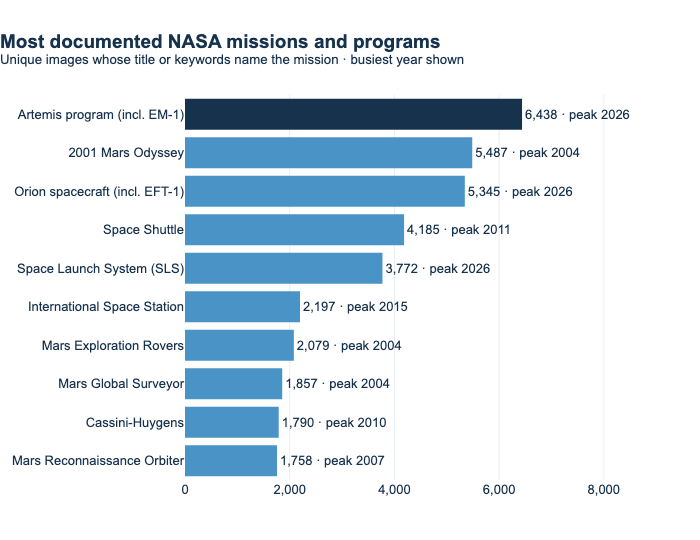

In [28]:
top_missions = mission_mentions.head(10)
fig_mission_rank = go.Figure(go.Bar(
    x=top_missions["images"], y=top_missions["mission"], orientation="h",
    marker_color=[NAVY if i == 0 else BLUE for i in range(len(top_missions))],
    text=[f"{n:,} · peak {y}" for n, y in zip(top_missions["images"], top_missions["peak_year"])],
    textposition="outside", cliponaxis=False,
))
fig_mission_rank.update_layout(
    title="<b>Most documented NASA missions and programs</b>"
          "<br><sup>Unique images whose title or keywords name the mission · busiest year shown</sup>",
    height=540, showlegend=False)
fig_mission_rank.update_yaxes(autorange="reversed", showgrid=False, title=None)
fig_mission_rank.update_xaxes(tickformat=",d", range=[0, top_missions["images"].max() * 1.35], title=None)
show_and_save(fig_mission_rank, "insight3_mission_keywords.png")

Which missions dominate particular years? For the top missions, here is where their records sit in time. Each row is scaled to its own busiest year, so you can compare *when* a mission was documented rather than how much.

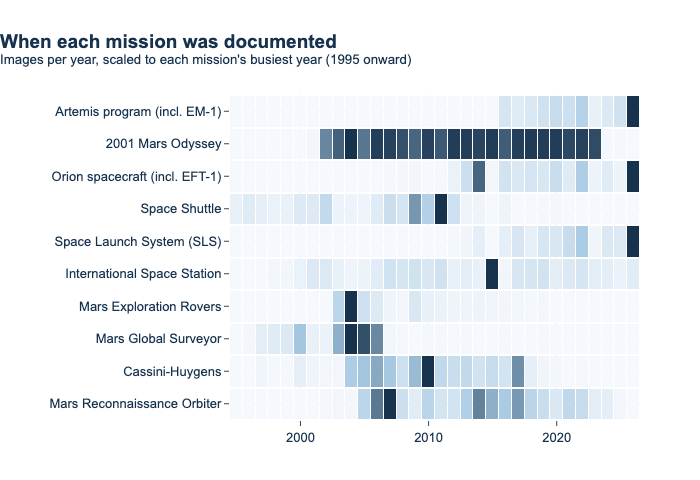

In [29]:
selected = top_missions["mission"].tolist()
by_year = sql(f"""
    WITH missions AS (
        SELECT * FROM unnest(CAST(:names AS text[]), CAST(:patterns AS text[])) AS m(mission, pattern)
    ), docs AS (
        SELECT EXTRACT(YEAR FROM r.date)::integer AS year,
               r.title || ' | ' || COALESCE((SELECT string_agg(k, ' | ')
                                             FROM jsonb_array_elements_text(r.keywords) AS k), '') AS text_value
        FROM nasa_records AS r WHERE {SCOPE} AND {HISTORICAL} AND r.date >= DATE '1995-01-01'
    )
    SELECT m.mission, d.year, COUNT(*) AS images
    FROM missions AS m JOIN docs AS d ON d.text_value ~* m.pattern
    GROUP BY 1, 2
""", names=selected, patterns=[rules.MISSION_ALIASES[m] for m in selected])
heat = by_year.pivot_table(index="mission", columns="year", values="images", fill_value=0).reindex(selected)
heat = heat.reindex(columns=range(1995, int(as_of_date[:4]) + 1), fill_value=0)
fig_heat = go.Figure(go.Heatmap(
    z=heat.div(heat.max(axis=1), axis=0).values, x=heat.columns, y=heat.index,
    customdata=heat.values, colorscale=[[0, "#F5F8FC"], [0.5, LIGHT_BLUE], [1, NAVY]], showscale=False,
    hovertemplate="<b>%{y}</b> · %{x}<br>%{customdata:,} images<extra></extra>", xgap=1, ygap=2,
))
fig_heat.update_layout(title="<b>When each mission was documented</b><br><sup>Images per year, scaled to each mission's busiest year (1995 onward)</sup>",
                       height=480, margin=dict(l=230))
fig_heat.update_yaxes(autorange="reversed")
show_and_save(fig_heat)

### 3.3 Credit sources

Is the Credit field a list of photographers? Let's look at the exact values first. We only normalize formatting for counting: brackets removed, `_` read as `/`, extra spaces collapsed, and NASA's long name shortened. The original text in PostgreSQL is untouched.

In [30]:
CREDIT_EXPR = r"REGEXP_REPLACE(REPLACE(BTRIM(BTRIM(r.credit), '()'), '_', '/'), '\s+', ' ', 'g')"
credit_sources = sql(f"""
    WITH credits AS (
        SELECT CASE WHEN {CREDIT_EXPR} ~* '^NASA( or National Aeronautics and Space Administration)?$'
                    THEN 'NASA' ELSE {CREDIT_EXPR} END AS credit
        FROM nasa_records AS r WHERE {SCOPE} AND r.credit ~ '[^[:space:]]'
    )
    SELECT credit, COUNT(*) AS images,
           CASE WHEN credit = 'NASA' THEN 'NASA (no individual named)'
                WHEN credit ~* '^NASA ?/' THEN 'NASA / named individual'
                ELSE 'Other attribution' END AS credit_format
    FROM credits GROUP BY credit ORDER BY images DESC, credit
""")
credited_total = int(credit_sources["images"].sum())
credit_formats = credit_sources.groupby("credit_format", as_index=False)["images"].sum().sort_values("images", ascending=False)
credit_formats["share"] = credit_formats["images"] / credited_total * 100
show_table(credit_sources.head(10).rename(columns={"credit": "Credit (normalized)", "images": "Images",
                                                   "credit_format": "Format"}), {"Images": "{:,.0f}"})
show_table(credit_formats.rename(columns={"credit_format": "Credit format", "images": "Images", "share": "Share"}),
           {"Images": "{:,.0f}", "Share": "{:.1f}%"})
print(f"{credit_sources['credit'].nunique():,} distinct normalized credit values across {credited_total:,} credited records.")

Credit (normalized),Images,Format
NASA/Bill Ingalls,"2,924",NASA / named individual
NASA/Kim Shiflett,"2,814",NASA / named individual
NASA,"1,811",NASA (no individual named)
NASA/Joel Kowsky,"1,316",NASA / named individual
NASA/Ben Smegelsky,"1,028",NASA / named individual
NASA/Aubrey Gemignani,"1,018",NASA / named individual
NASA/Frank Michaux,513,NASA / named individual
NASA/Glenn Benson,484,NASA / named individual
NASA/Cory Huston,443,NASA / named individual
NASA/Randy Beaudoin,419,NASA / named individual


Credit format,Images,Share
NASA / named individual,"16,157",68.0%
Other attribution,"5,778",24.3%
NASA (no individual named),"1,811",7.6%


776 distinct normalized credit values across 23,746 credited records.


Most credited records follow NASA's photo-credit format, *NASA/Name*, which names a person alongside the agency. But other values are organizations (for example *SpaceX*) or a person's name with no organization, and we can't reliably tell a staff photographer from an astronaut or a partner from the text alone. So we call this **Credit Sources**, not "top photographers".

### 3.4 Locations

Location values are free text with many spellings (*Kennedy Space Center, FL*, *KSC*, *VAB*, *O&C*). We group them with explicit patterns into **launch sites & launch processing**, **NASA centers & offices**, **landing & recovery areas**, **in orbit**, and **other places**.

In [31]:
location_params = {}
branches = []
for i, (group, pattern) in enumerate(rules.LOCATION_GROUPS.items()):
    location_params[f"p{i}"], location_params[f"g{i}"] = pattern, group
    branches.append(f"WHEN r.location ~* :p{i} THEN :g{i}")
location_params["other"] = rules.OTHER_LOCATION
LOCATION_CASE = "CASE " + " ".join(branches) + " ELSE :other END"

top_locations = sql(f"""
    SELECT MIN(BTRIM(r.location)) AS location, COUNT(*) AS images, MIN({LOCATION_CASE}) AS location_group
    FROM nasa_records AS r WHERE {SCOPE} AND r.location ~ '[^[:space:]]'
    GROUP BY LOWER(BTRIM(r.location)) ORDER BY images DESC, location LIMIT 10
""", **location_params)
location_groups = sql(f"""
    SELECT {LOCATION_CASE} AS location_group, COUNT(*) AS images
    FROM nasa_records AS r WHERE {SCOPE} AND r.location ~ '[^[:space:]]'
    GROUP BY 1 ORDER BY images DESC
""", **location_params)
located_total = int(location_groups["images"].sum())
location_groups["share"] = location_groups["images"] / located_total * 100
show_table(top_locations.rename(columns={"location": "Location", "images": "Images", "location_group": "Group"}),
           {"Images": "{:,.0f}"})
show_table(location_groups.rename(columns={"location_group": "Location group", "images": "Images", "share": "Share"}),
           {"Images": "{:,.0f}", "Share": "{:.1f}%"})

Location,Images,Group
"Kennedy Space Center, FL","9,795",Launch sites & launch processing
"Cape Canaveral, FL","2,772",Launch sites & launch processing
"Greenbelt, MD","2,014",NASA centers & offices
"Vandenberg AFB, CA","1,536",Launch sites & launch processing
Kennedy Space Center,832,Launch sites & launch processing
NASA Headquarters,589,NASA centers & offices
VAB,494,Launch sites & launch processing
KSC,429,Launch sites & launch processing
NASA MICHOUD ASSEMBLY FACILITY,428,NASA centers & offices
O&C,371,Launch sites & launch processing


Location group,Images,Share
Launch sites & launch processing,"24,372",70.4%
NASA centers & offices,"5,483",15.8%
Other places,"3,180",9.2%
Landing & recovery areas,"1,361",3.9%
In orbit,209,0.6%


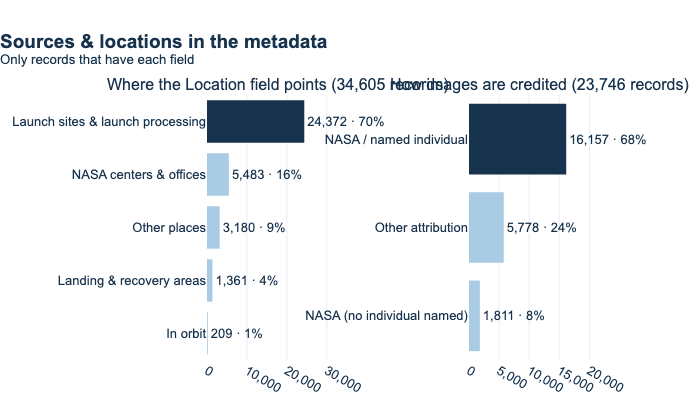

In [32]:
fig_sources = make_subplots(rows=1, cols=2, horizontal_spacing=0.3,
                            subplot_titles=(f"Where the Location field points ({located_total:,} records)",
                                            f"How images are credited ({credited_total:,} records)"))
fig_sources.add_bar(y=location_groups["location_group"], x=location_groups["images"], orientation="h",
                    marker_color=[NAVY] + [LIGHT_BLUE] * (len(location_groups) - 1),
                    text=[f"{n:,} · {s:.0f}%" for n, s in zip(location_groups["images"], location_groups["share"])],
                    textposition="outside", cliponaxis=False, row=1, col=1)
fig_sources.add_bar(y=credit_formats["credit_format"], x=credit_formats["images"], orientation="h",
                    marker_color=[NAVY] + [LIGHT_BLUE] * (len(credit_formats) - 1),
                    text=[f"{n:,} · {s:.0f}%" for n, s in zip(credit_formats["images"], credit_formats["share"])],
                    textposition="outside", cliponaxis=False, row=1, col=2)
fig_sources.update_layout(title="<b>Sources & locations in the metadata</b><br><sup>Only records that have each field</sup>",
                          height=420, showlegend=False, margin=dict(l=40, r=90))
fig_sources.update_yaxes(autorange="reversed", showgrid=False, automargin=True)
fig_sources.update_xaxes(tickformat=",d", range=[0, location_groups["images"].max() * 1.45], row=1, col=1)
fig_sources.update_xaxes(tickformat=",d", range=[0, credit_formats["images"].max() * 1.45], row=1, col=2)
show_and_save(fig_sources, "insight3_sources_locations.png", width=1400)

### 3.5 Two records behind the rankings

One image for the most documented science mission, and one from the busiest Space Shuttle year (chosen by a fixed rule: the most recent record with a descriptive title).

In [33]:
odyssey = sql(f"""
    SELECT r.source_id, r.title, r.date::text AS date, r.image_url, r.page_url, r.credit, '2001 Mars Odyssey' AS tag
    FROM nasa_records AS r
    WHERE {SCOPE} AND {HISTORICAL} AND r.keywords::text ~* 'mars odyssey' AND r.source_id LIKE 'PIA%'
      AND r.title !~ :id_only AND r.image_url LIKE '%~thumb.jpg'
    ORDER BY r.date DESC, r.source_id LIMIT 1
""", id_only=rules.ID_ONLY_TITLE)
shuttle_peak = int(mission_mentions.set_index("mission").loc["Space Shuttle", "peak_year"])
shuttle = sql(f"""
    SELECT r.source_id, r.title, r.date::text AS date, r.image_url, r.page_url, r.credit,
           'Space Shuttle · ' || :year AS tag
    FROM nasa_records AS r
    WHERE {SCOPE} AND EXTRACT(YEAR FROM r.date) = :year AND r.title ~* :pattern
      AND r.title !~ :id_only AND r.image_url LIKE '%~thumb.jpg'
    ORDER BY r.date DESC, r.source_id LIMIT 1
""", year=shuttle_peak, pattern=r"\matlantis\M|sts-135", id_only=rules.ID_ONLY_TITLE)
image_cards(pd.concat([odyssey, shuttle], ignore_index=True), "tag")

### 3.6 Key Findings

In [34]:
by_mission = mission_mentions.set_index("mission")
leader = mission_mentions.iloc[0]
odyssey_row = by_mission.loc["2001 Mars Odyssey"]
shuttle_row = by_mission.loc["Space Shuttle"]
odyssey_pia = sql(f"""
    SELECT COUNT(*) FILTER (WHERE r.source_id LIKE 'PIA%') AS pia, COUNT(*) AS n
    FROM nasa_records AS r WHERE {SCOPE} AND {HISTORICAL}
      AND (r.title || ' ' || r.keywords::text) ~* :p
""", p=rules.MISSION_ALIASES["2001 Mars Odyssey"]).iloc[0]
launch_share = location_groups.set_index("location_group").loc["Launch sites & launch processing", "share"]
named_share = credit_formats.set_index("credit_format").loc["NASA / named individual", "share"]
second_year = int(top_years.loc[1, "year"])
shuttle_context = ""
if int(shuttle_row["peak_year"]) == 2011:
    shuttle_context = ", the year of the final shuttle mission, STS-135 ([NASA](https://www.nasa.gov/mission/sts-135/))"
    if second_year == 2011:
        shuttle_context += "; 2011 is also the archive's second-busiest year" 
display(Markdown(f"""
- **{leader['mission']}** appears in **{int(leader['images']):,} unique images**, the most of any name we checked, with its busiest year in {int(leader['peak_year'])} (Artemis II launched on April 1, 2026, [NASA](https://www.nasa.gov/news-release/liftoff-nasa-launches-astronauts-on-historic-artemis-moon-mission/)). The most documented *science* mission is **2001 Mars Odyssey** ({int(odyssey_row['images']):,} images, {odyssey_pia['pia'] / odyssey_pia['n'] * 100:.2f}% of them JPL Photojournal releases, busiest in {int(odyssey_row['peak_year'])}).
- **Space Shuttle** mentions ({int(shuttle_row['images']):,} images) peak in **{int(shuttle_row['peak_year'])}** ({int(shuttle_row['peak_year_images']):,} images){shuttle_context}.
- **{launch_share:.0f}%** of records with a Location point to launch sites or launch-processing facilities (top value: *{top_locations.loc[0, 'location']}*), so Location usually describes where a mission was prepared, not where a planet was photographed. Among credited records, **{named_share:.0f}%** use the *NASA/Name* format. Credit exists for only {credited_total / total_images * 100:.1f}% of records, so treat these as **credit sources**, not a photographer ranking.
"""))


- **Artemis program (incl. EM-1)** appears in **6,438 unique images**, the most of any name we checked, with its busiest year in 2026 (Artemis II launched on April 1, 2026, [NASA](https://www.nasa.gov/news-release/liftoff-nasa-launches-astronauts-on-historic-artemis-moon-mission/)). The most documented *science* mission is **2001 Mars Odyssey** (5,487 images, 100.00% of them JPL Photojournal releases, busiest in 2004).
- **Space Shuttle** mentions (4,185 images) peak in **2011** (730 images), the year of the final shuttle mission, STS-135 ([NASA](https://www.nasa.gov/mission/sts-135/)); 2011 is also the archive's second-busiest year.
- **70%** of records with a Location point to launch sites or launch-processing facilities (top value: *Kennedy Space Center, FL*), so Location usually describes where a mission was prepared, not where a planet was photographed. Among credited records, **68%** use the *NASA/Name* format. Credit exists for only 32.1% of records, so treat these as **credit sources**, not a photographer ranking.


---
## Section 4 — Supplementary Data Quality Checks

These are the descriptive checks from our first EDA. They support the three insights (for example, the completeness numbers explain why Credit and Location rankings cover only part of the archive), but they are not the main story.

### 4.1 Metadata completeness

How often is each field filled in? Empty strings, whitespace, and empty keyword arrays count as missing.

In [35]:
metadata_sql = """
SELECT COUNT(*) AS total_images,
       COUNT(*) FILTER (WHERE title ~ '[^[:space:]]') AS title,
       COUNT(*) FILTER (WHERE date IS NOT NULL AND isfinite(date)) AS date,
       COUNT(*) FILTER (WHERE image_url ~ '[^[:space:]]') AS image_url,
       COUNT(*) FILTER (WHERE explanation ~ '[^[:space:]]') AS explanation,
       COUNT(*) FILTER (WHERE credit ~ '[^[:space:]]') AS credit,
       COUNT(*) FILTER (WHERE center ~ '[^[:space:]]') AS center,
       COUNT(*) FILTER (WHERE location ~ '[^[:space:]]') AS location,
       COUNT(*) FILTER (WHERE CASE WHEN jsonb_typeof(keywords) = 'array' THEN
           EXISTS (SELECT 1 FROM jsonb_array_elements(keywords) AS keyword(value)
                   WHERE jsonb_typeof(value) = 'string'
                     AND (value #>> '{}') ~ '[^[:space:]]')
           ELSE FALSE END) AS keywords,
       COUNT(*) FILTER (WHERE keywords IS NOT NULL AND jsonb_typeof(keywords) <> 'array') AS non_array_keywords
FROM nasa_records
WHERE source_api = 'nasa_library' AND media_type = 'image'
"""
metadata_counts = pd.read_sql(text(metadata_sql), connection).iloc[0]
assert metadata_counts["total_images"] == total_images
field_labels = {"title": "Title", "date": "Date", "image_url": "Image URL", "explanation": "Explanation",
                "credit": "Credit", "center": "Center", "location": "Location", "keywords": "Keywords"}
metadata_summary = pd.DataFrame([
    {"field": field, "Metadata Field": label, "Available Records": int(metadata_counts[field])}
    for field, label in field_labels.items()
])
metadata_summary["Missing Records"] = total_images - metadata_summary["Available Records"]
metadata_summary["Completeness Percentage"] = metadata_summary["Available Records"] / total_images * 100
metadata_summary = metadata_summary.sort_values("Completeness Percentage", ascending=False, kind="stable").reset_index(drop=True)

In [36]:
display(metadata_summary.drop(columns="field").style.format({
    "Available Records": "{:,.0f}", "Missing Records": "{:,.0f}", "Completeness Percentage": "{:.2f}%",
}).hide(axis="index").set_table_styles(TABLE_STYLE))

Metadata Field,Available Records,Missing Records,Completeness Percentage
Title,"73,937",0,100.00%
Date,"73,937",0,100.00%
Image URL,"73,937",0,100.00%
Explanation,"73,923",14,99.98%
Center,"73,895",42,99.94%
Keywords,"56,520","17,417",76.44%
Location,"34,605","39,332",46.80%
Credit,"23,746","50,191",32.12%


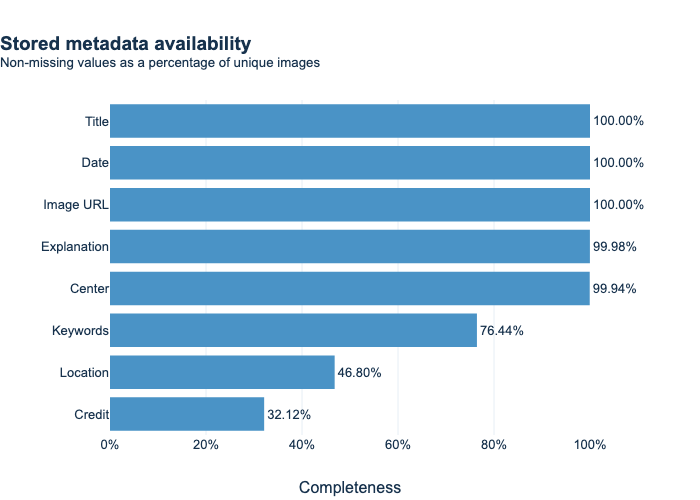

In [37]:
fig_metadata = px.bar(
    metadata_summary, x="Completeness Percentage", y="Metadata Field", orientation="h",
    custom_data=["Available Records", "Missing Records"],
    title="<b>Stored metadata availability</b><br><sup>Non-missing values as a percentage of unique images</sup>",
)
fig_metadata.update_traces(
    marker_color=BLUE, text=metadata_summary["Completeness Percentage"],
    texttemplate="%{text:.2f}%", textposition="outside", cliponaxis=False,
    hovertemplate="<b>%{y}</b><br>Available: %{customdata[0]:,}<br>Missing: %{customdata[1]:,}<br>Completeness: %{x:.2f}%<extra></extra>",
)
fig_metadata.update_xaxes(range=[0, 100], ticksuffix="%", dtick=20, title="Completeness")
fig_metadata.update_yaxes(autorange="reversed", title=None, showgrid=False)
fig_metadata.update_layout(height=500, margin=dict(l=110, r=110, t=100, b=65), showlegend=False)
fig_metadata.show(config=CHART_CONFIG)

### 4.2 Topic distribution

How the nine search topics split the image–topic relationships. One image can match several topics, so these shares describe matches, not unique images.

In [38]:
# Reuse the original topic aggregation, now against the expanded database.
topic_sql = """
SELECT m.search_keyword AS topic,
       COUNT(DISTINCT (r.source_api, r.source_id)) AS topic_matches
FROM nasa_records AS r
JOIN nasa_search_matches AS m
  ON r.source_api = m.source_api AND r.source_id = m.source_id
WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
GROUP BY m.search_keyword
ORDER BY topic_matches DESC, topic
"""
topic_counts = pd.read_sql(text(topic_sql), connection)
topic_counts["topic_label"] = topic_counts["topic"].str.title()
topic_counts["match_share"] = topic_counts["topic_matches"] / total_relationships * 100
topic_counts["image_share"] = topic_counts["topic_matches"] / total_images * 100
assert topic_counts["topic_matches"].sum() == total_relationships

In [39]:
topic_summary = topic_counts[["topic_label", "topic_matches", "match_share", "image_share"]].rename(columns={
    "topic_label": "Search Topic", "topic_matches": "Topic Matches",
    "match_share": "Share of All Matches", "image_share": "Share of Unique Images",
})
display(topic_summary.style.format({"Topic Matches": "{:,.0f}", "Share of All Matches": "{:.1f}%",
                                    "Share of Unique Images": "{:.1f}%"})
        .hide(axis="index").set_table_styles(TABLE_STYLE))

Search Topic,Topic Matches,Share of All Matches,Share of Unique Images
Earth,"41,211",51.0%,55.7%
Mars,"26,903",33.3%,36.4%
Saturn,"4,238",5.2%,5.7%
Mercury,"2,907",3.6%,3.9%
Jupiter,"2,639",3.3%,3.6%
Galaxy,"1,748",2.2%,2.4%
Venus,786,1.0%,1.1%
Neptune,265,0.3%,0.4%
Uranus,112,0.1%,0.2%


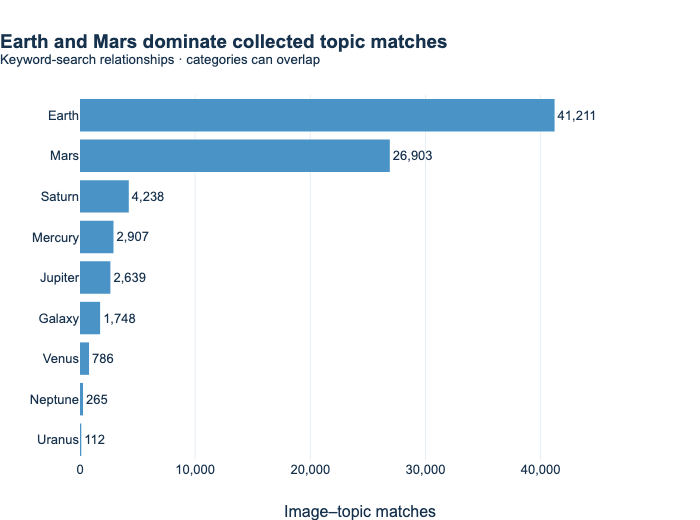

In [40]:
fig_topics = px.bar(
    topic_counts, x="topic_matches", y="topic_label", orientation="h",
    text="topic_matches", custom_data=["match_share"],
    title="<b>Earth and Mars dominate collected topic matches</b><br><sup>Keyword-search relationships · categories can overlap</sup>",
    labels={"topic_matches": "Image–topic matches", "topic_label": "Search topic"},
)
fig_topics.update_traces(
    marker_color=BLUE, texttemplate="%{x:,}", textposition="outside", cliponaxis=False,
    hovertemplate="<b>%{y}</b><br>Matches: %{x:,}<br>Share of all matches: %{customdata[0]:.1f}%<extra></extra>",
)
fig_topics.update_yaxes(autorange="reversed", title=None, showgrid=False)
fig_topics.update_xaxes(range=[0, topic_counts["topic_matches"].max() * 1.18], tickformat=",d")
fig_topics.update_layout(height=520, showlegend=False)
fig_topics.show(config=CHART_CONFIG)

### 4.3 Topic overlap

Which topics share images, and how many images match more than one topic.

In [41]:
overlap_sql = """
WITH matches AS (
    SELECT DISTINCT m.source_api, m.source_id, m.search_keyword
    FROM nasa_search_matches AS m
    JOIN nasa_records AS r USING (source_api, source_id)
    WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
)
SELECT a.search_keyword AS topic_a, b.search_keyword AS topic_b,
       COUNT(*) AS shared_images
FROM matches AS a
JOIN matches AS b
  ON a.source_api = b.source_api AND a.source_id = b.source_id
 AND a.search_keyword < b.search_keyword
GROUP BY a.search_keyword, b.search_keyword
ORDER BY shared_images DESC, topic_a, topic_b
"""
pair_counts = pd.read_sql(text(overlap_sql), connection)
image_multiplicity = pd.read_sql(text("""
    WITH topics_per_image AS (
        SELECT r.source_api, r.source_id, COUNT(DISTINCT m.search_keyword) AS topic_count
        FROM nasa_records AS r
        LEFT JOIN nasa_search_matches AS m USING (source_api, source_id)
        WHERE r.source_api = 'nasa_library' AND r.media_type = 'image'
        GROUP BY r.source_api, r.source_id
    )
    SELECT topic_count, COUNT(*) AS unique_images
    FROM topics_per_image GROUP BY topic_count ORDER BY topic_count
"""), connection)
assert image_multiplicity["unique_images"].sum() == total_images
assert (image_multiplicity["topic_count"] * image_multiplicity["unique_images"]).sum() == total_relationships

# Use the same ordering as the topic-distribution chart.
topic_order = topic_counts["topic"].tolist()
topic_totals = topic_counts.set_index("topic")["topic_matches"]
overlap_matrix = pd.DataFrame(0, index=topic_order, columns=topic_order, dtype="int64")
for topic in topic_order:
    overlap_matrix.loc[topic, topic] = int(topic_totals[topic])
for row in pair_counts.itertuples(index=False):
    overlap_matrix.loc[row.topic_a, row.topic_b] = row.shared_images
    overlap_matrix.loc[row.topic_b, row.topic_a] = row.shared_images
assert overlap_matrix.equals(overlap_matrix.T)
pair_counts["a_images"] = pair_counts["topic_a"].map(topic_totals)
pair_counts["b_images"] = pair_counts["topic_b"].map(topic_totals)
pair_counts["smaller_topic_share"] = pair_counts["shared_images"] / pair_counts[["a_images", "b_images"]].min(axis=1) * 100
pair_counts["jaccard"] = pair_counts["shared_images"] / (
    pair_counts["a_images"] + pair_counts["b_images"] - pair_counts["shared_images"]) * 100

In [42]:
pair_summary = pair_counts.head(10).copy()
pair_summary["Topic Pair"] = pair_summary["topic_a"].str.title() + " / " + pair_summary["topic_b"].str.title()
pair_summary = pair_summary[["Topic Pair", "shared_images", "smaller_topic_share", "jaccard"]].rename(columns={
    "shared_images": "Shared Unique Images", "smaller_topic_share": "Share of Smaller Topic", "jaccard": "Jaccard Overlap",
})
display(pair_summary.style.format({"Shared Unique Images": "{:,.0f}", "Share of Smaller Topic": "{:.1f}%",
                                   "Jaccard Overlap": "{:.1f}%"})
        .hide(axis="index").set_table_styles(TABLE_STYLE))

Topic Pair,Shared Unique Images,Share of Smaller Topic,Jaccard Overlap
Earth / Mars,"3,699",13.7%,5.7%
Earth / Galaxy,688,39.4%,1.6%
Earth / Saturn,533,12.6%,1.2%
Earth / Jupiter,398,15.1%,0.9%
Earth / Mercury,356,12.2%,0.8%
Jupiter / Mars,332,12.6%,1.1%
Earth / Venus,308,39.2%,0.7%
Jupiter / Saturn,222,8.4%,3.3%
Mercury / Venus,172,21.9%,4.9%
Mars / Venus,121,15.4%,0.4%


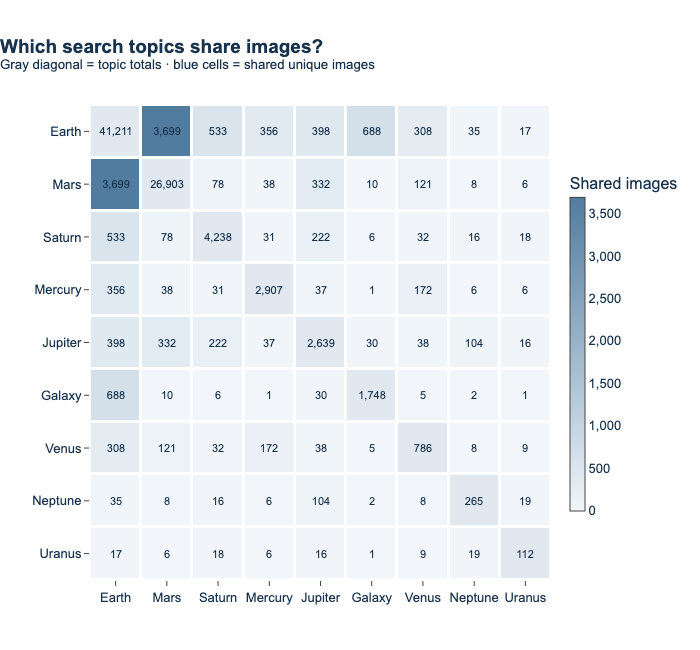

In [43]:
matrix_labels = [topic.title() for topic in topic_order]
shared_values = [[None if a == b else int(overlap_matrix.loc[a, b]) for b in topic_order] for a in topic_order]
diagonal_values = [[int(overlap_matrix.loc[a, b]) if a == b else None for b in topic_order] for a in topic_order]
max_shared = int(pair_counts["shared_images"].max()) if not pair_counts.empty else 0
fig_overlap = go.Figure()
fig_overlap.add_trace(go.Heatmap(
    z=shared_values, x=matrix_labels, y=matrix_labels, zmin=0, zmax=max(1, max_shared),
    colorscale=[[0, "#F2F6FA"], [0.45, "#A6BED1"], [1, "#527C9F"]],
    texttemplate="%{z:,}", textfont=dict(size=11, color=NAVY), xgap=3, ygap=3,
    colorbar=dict(title="Shared images", tickformat=",d", thickness=15, len=0.75),
    hoverongaps=False,
    hovertemplate="<b>%{y} / %{x}</b><br>Shared unique images: %{z:,}<extra></extra>",
))
fig_overlap.add_trace(go.Heatmap(
    z=diagonal_values, x=matrix_labels, y=matrix_labels,
    colorscale=[[0, "#E1E8EF"], [1, "#E1E8EF"]], showscale=False,
    texttemplate="%{z:,}", textfont=dict(size=11, color=NAVY), xgap=3, ygap=3,
    hoverongaps=False,
    hovertemplate="<b>%{y}</b><br>Topic total: %{z:,}<br>Diagonal: not an additional overlap<extra></extra>",
))
fig_overlap.update_layout(
    title="<b>Which search topics share images?</b><br><sup>Gray diagonal = topic totals · blue cells = shared unique images</sup>",
    height=650, margin=dict(l=90, r=120, t=105, b=70),
    xaxis=dict(title=None, side="bottom", tickangle=0, showgrid=False),
    yaxis=dict(title=None, autorange="reversed", showgrid=False),
)
fig_overlap.show(config=CHART_CONFIG)

In [44]:
multi_topic = int(image_multiplicity.loc[image_multiplicity["topic_count"] >= 2, "unique_images"].sum())
top_pair = pair_counts.iloc[0]
display(Markdown(
    f"**{multi_topic:,} images ({multi_topic / total_images * 100:.1f}%)** match two or more topics. "
    f"The largest overlap is **{top_pair['topic_a'].title()} / {top_pair['topic_b'].title()}** with "
    f"**{int(top_pair['shared_images']):,}** shared images (Jaccard {top_pair['jaccard']:.1f}%). "
    "This is why every count in this notebook uses distinct NASA IDs."
))

**6,482 images (8.8%)** match two or more topics. The largest overlap is **Earth / Mars** with **3,699** shared images (Jaccard 5.7%). This is why every count in this notebook uses distinct NASA IDs.

### 4.4 Duplicate checks and future-dated records

The profile in Section 0 already asserted that NASA IDs are unique and every relationship points to an existing image. Here we look at the future-dated records. Their NASA IDs contain an earlier date than the stored one, which suggests a metadata typo, but we don't rewrite the data.

In [45]:
# Retain the exact metadata values and show a small, reproducible anomaly sample.
future_records = pd.read_sql(text("""
    SELECT source_id, date::text AS stored_date, title
    FROM nasa_records
    WHERE source_api = 'nasa_library' AND media_type = 'image'
      AND isfinite(date) AND date > CURRENT_DATE
    ORDER BY date DESC, source_id
    LIMIT 10
"""), connection)
future_examples = future_records.rename(columns={"source_id": "NASA ID", "stored_date": "Stored Date", "title": "Title"})
display(future_examples.style.hide(axis="index").set_table_styles(TABLE_STYLE))
display(Markdown(
    f"**Date-quality note.** There are **{int(profile['future_dates']):,} future-dated records** as of {as_of_date}. "
    "The displayed KSC IDs contain earlier calendar dates than the stored metadata dates. "
    "This suggests metadata anomalies, but an ID alone is not enough to establish a corrected date. "
    "We retain all rows and exclude future dates only from the historical trend."
))

NASA ID,Stored Date,Title
KSC-20240724-PH-CSH01_0001,2031-07-24,Artemis II Core Stage Offload
KSC-20221116-PH-CLC03_0055,2029-11-16,Artemis I Liftoff
KSC-20221116-PH-CLC03_0057,2029-11-16,Artemis I Liftoff
KSC-20221116-PH-CLC03_0061,2029-11-16,Artemis I Liftoff
KSC-20200729-PH-ILW01_0004,2027-07-29,Mars 2020 NASA Administrator Briefing
KSC-20200729-PH-ILW01_0007,2027-07-29,Mars 2020 NASA Administrator Briefing
KSC-20200729-PH-ILW01_0008,2027-07-29,Mars 2020 NASA Administrator Briefing


**Date-quality note.** There are **7 future-dated records** as of 2026-11-25. The displayed KSC IDs contain earlier calendar dates than the stored metadata dates. This suggests metadata anomalies, but an ID alone is not enough to establish a corrected date. We retain all rows and exclude future dates only from the historical trend.

### 4.5 Records dated before 1958

During a project review, the Archive Search date picker went all the way back to **1912**. Let's look at every record dated before NASA was founded (October 1, 1958) and check whether its image actually loads.

In [46]:
pre_nasa = sql(f"""
    SELECT r.source_id, r.date::text AS stored_date, r.center, r.title, r.image_url, r.page_url,
           LEFT(r.explanation, 420) AS description_start,
           (SELECT string_agg(m.search_keyword, ', ' ORDER BY m.search_keyword) FROM nasa_search_matches AS m
             WHERE m.source_api = r.source_api AND m.source_id = r.source_id) AS topics
    FROM nasa_records AS r WHERE {SCOPE} AND r.date < DATE '1958-01-01'
    ORDER BY r.date, r.source_id
""")


def thumbnail_status(url):
    """HTTP status of the stored thumbnail URL (HEAD request, no download)."""
    try:
        return requests.head(url, timeout=10, allow_redirects=True).status_code
    except requests.RequestException as error:
        return type(error).__name__


pre_nasa["thumbnail_http"] = pre_nasa["image_url"].map(thumbnail_status)
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 50):
    display(pre_nasa[["source_id", "stored_date", "center", "title", "topics", "thumbnail_http"]])
print(f"{len(pre_nasa)} records before 1958 · thumbnail responses: "
      f"{pre_nasa['thumbnail_http'].value_counts().to_dict()}")

,source_id,stored_date,center,title,topics,thumbnail_http
0,6975130,1912-03-23,MSFC,Wernher von Braun,saturn,200
1,GRC-1949-C-23011,1949-02-23,GRC,NACA Computers Take Readings From Manometer Boards,mercury,200
2,0400529,1950-01-01,MSFC,Saturn Apollo Program,saturn,200
3,9131097,1950-01-01,MSFC,Wernher von Braun,earth,200
4,9306794,1950-01-01,MSFC,Mercury Project,"earth, mercury",200
5,9306795,1950-01-01,MSFC,Mercury Project,mercury,200
6,6521805,1951-01-23,MSFC,Saturn Apollo Program,saturn,200
7,GRC-1951-C-27175,1951-02-23,GRC,Manometer Boards below the 8- by 6-Foot Supersonic Wind Tunnel,mercury,200
8,ARC-1969-A-16712,1951-12-06,ARC,ARC-1969-A-16712,mars,200
9,GRC-1952-C-29212,1952-02-23,GRC,NACA Computer Operates an IBM Telereader,mercury,200


20 records before 1958 · thumbnail responses: {200: 20}


In [47]:
# The earliest record, plus two whose description disagrees with the stored date.
for source_id in ["6975130", "6521805", "0400529"]:
    row = pre_nasa.set_index("source_id").loc[source_id]
    print(f"{source_id} · stored {row['stored_date']} · {row['title']}\n  {row['description_start']}…\n")
image_cards(pre_nasa[pre_nasa["source_id"].isin(["6975130", "GRC-1949-C-23011", "5705665"])]
            .assign(date=lambda f: f["stored_date"], credit=None, tag="Pre-1958 record"), "tag")

6975130 · stored 1912-03-23 · Wernher von Braun
  This is a childhood picture of Dr. von Braun (center) with his brothers. Dr. Wernher von Braun was born in Wirsitz, Germany, March 23, 1912. His childhood dreams of marned space flight were fulfilled when giant Saturn rockets, developed under his direction at NASA's Marshall Space Flight Center, boosted the manned Apollo spacecraft to the Moon. His life was dedicated to expanding man's knowledge through the explorati…

6521805 · stored 1951-01-23 · Saturn Apollo Program
  The photograph shows the completed Saturn 1 S-1 stage (booster) during the checkout in the Marshall Space Flight Center, building 4705, January 23, 1961. The Saturn I S-I stage had eight H-1 engines clustered, using liquid oxygen/kerosene-1 (LOX/RP-1) propellants capable of producing a total of 1,500,000 pounds of thrust.…

0400529 · stored 1950-01-01 · Saturn Apollo Program
  This historical photograph is of the Apollo Space Program Leaders. An inscription appears at 

**What we found.**

- **The 1912 record is real archive material, not a broken row.** It is a childhood photo of Wernher von Braun with his brothers. Its stored date, March 23, 1912, is his birth date, not when the photo was taken.
- **Most pre-1958 records are genuine historical photos** from NASA's predecessor NACA (Lewis/Glenn, Ames, Langley) and the Army rocket team that later became Marshall. Examples are "human computers" reading manometer boards and Jupiter missile tests.
- **Some stored dates are approximate or inconsistent with the record's own description.** Several are placeholder January 1 dates. `0400529`, a photo of NASA's Apollo program leaders signed after Apollo 11, is stored as January 1, 1950. `6521805` is stored as January 23, 1951, but its description says the photo shows a Saturn I stage on January 23, 1961. One record (`9142274`) even has the title `n/a`.
- **Topic matches can be accidental.** NACA manometer photos matched "Mercury" (the liquid metal in manometers), and von Braun photos matched "Saturn" (the rocket).
- **All thumbnails load (HTTP 200).** The SQL query returns these records correctly. The poor experience came from the UI: a calendar that started in 1912, with long runs of empty years before 1958.

**What we changed (dashboard only, data untouched).** Archive Search now offers a **Year** list starting in 1958 that only shows years with matching records. Older material stays one click away under **Historical Archive & custom dates**, with a note that NASA was established in 1958 and that dates reflect archived metadata.

---
## Section 5 — Sources & Reproducibility

**NASA sources used for historical context** (all opened and checked; dates as stated on the page):

- GPM launch, Feb 27, 2014: https://gpm.nasa.gov/resources/faq/when-did-gpm-launch
- TDRS-L launch, Jan 23, 2014: https://www.nasa.gov/image-article/tracking-data-relay-satellite-launch-lights-up-night-sky/
- OCO-2 launch, Jul 2, 2014: https://www.nasa.gov/news-release/nasa-launches-new-carbon-sensing-mission-to-monitor-earths-breathing-2/ and https://www.nasa.gov/missions/oco-2/oco-2-lifts-off-on-carbon-counting-mission/
- MAVEN Mars orbit insertion, Sep 21, 2014: https://science.nasa.gov/mission/maven/
- Project Morpheus / ALHAT free flights, Dec 2013 – Dec 15, 2014: https://www.nasa.gov/technology/morpheus-team-completes-alhat-system-tests-on-prototype-lander/
- Orion EFT-1, Dec 5, 2014: https://www.nasa.gov/mission/exploration-flight-test-1/
- SMAP launch, Jan 31, 2015: https://www.nasa.gov/reference/lsp-primary-launches-archive/
- STS-135, the final Space Shuttle mission (Jul 8–21, 2011): https://www.nasa.gov/mission/sts-135/
- Artemis II launch, Apr 1, 2026: https://www.nasa.gov/news-release/liftoff-nasa-launches-astronauts-on-historic-artemis-moon-mission/
- NASA history (agency established 1958): https://www.nasa.gov/history/
- FY2014 operating plan (Earth Science $1,824.9M; Planetary Science $1,343.4M): https://www.nasa.gov/wp-content/uploads/2018/02/fy-2014-nasa-operating-plan-june-2014.pdf
- Images and metadata: NASA Image and Video Library, https://images.nasa.gov

**Method notes.**

- Every query runs in one read-only `REPEATABLE READ` transaction. The notebook never writes to the database and never creates tables or indexes.
- Counts use distinct NASA IDs. Topic filters use `EXISTS`, and multi-mission counts use a deduplicated union.
- All text rules (mission aliases, title groups, location groups) live in `dashboard/analysis_rules.py` and are shared with the Streamlit dashboard, which runs the same SQL live.
- Keyword and credit cleaning happens only inside queries; stored values are unchanged.
- The manual review in Section 2.4 uses a fixed hash order, so it returns the same sample on the same data.
- Exported charts are in `assets/eda/`. Re-running the notebook overwrites them.

In [48]:
# Final reconciliation against the snapshot, then close the read-only transaction.
assert len(topic_counts) == int(relationship_profile["search_topics"])
assert topic_counts["topic_matches"].sum() == total_relationships
assert historical_total + int(profile["future_dates"]) + int(profile["missing_dates"]) + int(profile["nonfinite_dates"]) == total_images
assert image_multiplicity["unique_images"].sum() == total_images
assert (metadata_summary["Available Records"] + metadata_summary["Missing Records"]).eq(total_images).all()
assert content_table.values.sum() == center_ranking.set_index("center").loc[focus, "images"].sum()
assert credited_total == int(metadata_counts["credit"]) and located_total == int(metadata_counts["location"])
assert all(path.is_file() and path.stat().st_size > 10_000 for path in exported_files)
for figure in [fig_trend, fig_missions, fig_centers, fig_content, fig_mission_rank, fig_heat, fig_sources,
               fig_topics, fig_overlap, fig_metadata]:
    figure.to_json(validate=True)

snapshot.rollback()
connection.close()
engine.dispose()
print(f"Validation passed · {total_images:,} unique images · {total_relationships:,} relationships · "
      f"{len(topic_counts)} topics · analysis date {as_of_date}")
print("Exported charts:", ", ".join(path.name for path in exported_files))

Validation passed · 73,937 unique images · 80,809 relationships · 9 topics · analysis date 2026-11-25
Exported charts: insight1_historical_peak.png, insight1_mission_comparison.png, insight2_nasa_centers.png, insight2_content_patterns.png, insight3_mission_keywords.png, insight3_sources_locations.png
